# Car Accident Prediction

---

**Входные данные**

Удаленная база данных, содержащая информацию о дорожно-транспортных происшествиях (ДТП).

---

**Цель**

Изучить идеи заказчика и сделать вывод об их реализуемости.

---

**Задачи:**  

- загрузить данные из удаленной БД;
- провести первичное исследование данных;  
- выполнить анализ факторов ДТП;
- подготовить данные для моделей;
- построить несколько различных моделей;
- выбрать лучшую модель;
- проанализировать выбранную модель;
- проанализировать основные факторы, влияющие на вероятность ДТП;
- сделайте вывод: насколько возможно создание адекватной системы оценки риска при выдаче авто;
- предложить: какие факторы необходимо собирать, чтобы улучшить модель.

---

## Intro

**Пояснения**

---

Постоянные таблицы с данными начинаются со слова **data** .  
Временные таблицы с данными начинаются со слова **df** .  

---

Код ячеек максимально независим друг от друга, чтобы свободно манипулировать ячейками.

---

Промежуточные выводы выделены так:

> Промежуточный вывод.

---

## Initial

### Imports

In [101]:
import pandas as pd
import numpy as np

import os
import json
import warnings
import joblib
from sqlalchemy import create_engine, text
from datetime import date, time, datetime
from time import time

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
import plotly.graph_objects as go
import plotly.io as pio

import phik

from sklearn.feature_selection import mutual_info_classif, mutual_info_regression
from sklearn.compose import ColumnTransformer, make_column_transformer, make_column_selector
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder, SplineTransformer, FunctionTransformer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline, make_pipeline, FeatureUnion

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import RidgeClassifier, SGDClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

import optuna
from optuna.distributions import FloatDistribution, IntDistribution, CategoricalDistribution

from sklearn.metrics import f1_score, ConfusionMatrixDisplay
from yellowbrick.classifier import PrecisionRecallCurve, ClassPredictionError, ROCAUC

from sklearn.inspection import permutation_importance

### Constants

In [102]:
# common constants

PATH_LOCAL = 'datasets/'                               # local path to data
CR = '\n'                                              # new line
RANDOM_STATE = RANDOM_SEED = RS = 88                   # random_state

In [103]:
import os
# database connection config

USER = 'praktikum_student'                             # имя пользователя
PSWD = os.environ.get('PRACTICUM_DB_PASSWORD', '')                                # пароль
HOST = 'rc1b-wcoijxj3yxfsf3fs.mdb.yandexcloud.net'     # хост подключения
PORT = '6432'                                          # порт подключения
DB = 'data-science-vehicle-db'                         # название базы данных

# create connection

connection_string = f'postgresql://{USER}:{PSWD}@{HOST}:{PORT}/{DB}'
engine = create_engine(connection_string)

In [104]:
# model

TARGET = 'at_fault'                                    # target name
SCORING = 'f1'                                         # target metric
VALID_FRAC = 0.20                                      # delayed sampling fraction
N_CV = 5                                               # number of folds during cross-validation

N_TRIALS = 100                                         # max of tries when Optuna optimization run
TIMEOUT = 300                                          # max time when Optuna optimization run

In [105]:
# estimators list (comment/uncomment estimator to skip/use)

ESTIMATOR_LIST = [
                  'Dummy',
                  'Ridge',
                  'SGD',
                  'HistGB',
                #   'RandomForest',
                  'XGBoost',
                  'LightGBM',
                 ]

### Functions

In [106]:
def sql_query(query_text):
    
    with engine.begin() as conn:
        return pd.read_sql_query(text(query_text), conn)

In [107]:
def reduce_memory_usage(df: pd.DataFrame, verbose='full'):
    '''
    Sets the optimal data type based on a range of values.
    Needs to be improved for unsigned integers!
    '''

    start_mem = df.memory_usage().sum() / 1024**2

    numerical_columns = df.select_dtypes(include=np.number).columns.to_list()
    
    for col in numerical_columns:
        
        if verbose == 'full':
            print(f'Optimising column {f.BOLD}{col}{f.END}', end='... ')
        
        min_value, max_value = df[col].min(), df[col].max()
        
        if 'int' in str(df[col].dtype):
            if min_value > np.iinfo('int8').min and max_value < np.iinfo('int8').max:
                df[col] = df[col].astype('int8')
            elif min_value > np.iinfo('int16').min and max_value < np.iinfo('int16').max:
                df[col] = df[col].astype('int16')
            elif min_value > np.iinfo('int32').min and max_value < np.iinfo('int32').max:
                df[col] = df[col].astype('int32')
            elif min_value > np.iinfo('int64').min and max_value < np.iinfo('int64').max:
                df[col] = df[col].astype('int64')
        
        if 'float' in str(df[col].dtype):
#             if min_value > np.finfo('float16').min and max_value < np.finfo('float16').max:
#                 df[col] = df[col].astype('float16')
            if min_value > np.finfo('float32').min and max_value < np.finfo('float32').max:
                df[col] = df[col].astype('float32')
            elif min_value > np.finfo('float64').min and max_value < np.finfo('float64').max:
                df[col] = df[col].astype('float64')

        if verbose == 'full':
            print('Done')
            
    end_mem = df.memory_usage().sum() / 1024**2

    if verbose == 'short':
        print(f'Memory usage before optimization: {start_mem:.3f} MB')
        print(f'Memory usage after optimization: {end_mem:.3f} MB')
        print(f'Memory usage reduced about {(start_mem-end_mem)/start_mem:.0%}')

    return df

In [108]:
def load_data(data_name, file_extension='csv', separator=',', query=''):
    '''
    Загружает датасет по локальному пути.
    Если указанный путь(файл) не существует:
        формирует SQL-запрос и загружает данные из удаленной базы данных;
        сохраняет данные локально.
    '''

    print(f'{f.BOLD}{data_name}{f.END} in process...')
    
    path_local = f'{PATH_LOCAL}{data_name}.{file_extension}'
    
    if os.path.exists(path_local):
        df = pd.read_csv(path_local, sep=separator)                               # локальная загрузка файла
        df = reduce_memory_usage(df, verbose='short')                             # оптимизация размера занимаемой памяти
        print(f'{f.BOLD}{data_name}{f.END} successfully loaded from local storage{CR}')        
        return df

    else:
        if query == '':
            query = f'SELECT * FROM {data_name}'                                  # текст запроса
        df = sql_query(query)                                                     # запрос к БД
        df = reduce_memory_usage(df, verbose='short')                             # оптимизация размера занимаемой памяти
        df.to_csv(f'{PATH_LOCAL}{data_name}.{file_extension}', index=False)       # сохранение локально
        print(f'{f.BOLD}{data_name}{f.END} successfully loaded from remote database and saved to local storage{CR}')
        return df

In [109]:
def var_name(var):
    '''
    var name determination
    '''
    return [name for name in globals() if globals()[name] is var][0]

In [110]:
def basic_info(df: pd.DataFrame, sample_type='sample', samples=5, describe='all'):
    '''
    first info about dataframe: info(), sample()/head()/tail(), describe()
    '''
    
    # title (name of dataframe)
    
    print(f'\n\n {f.BOLD}{var_name(df)}{f.END}', '≋'*30)


    # method info()
    
    print('\n\n--- method info() ---\n')
    print(df.info())

    
    # several random records
    
    print(f'\n\n--- method {sample_type}({samples}) ---')
    
    if sample_type == 'sample':
        display(df.sample(samples))
    elif sample_type == 'head':
        display(df.head(samples))
    elif sample_type == 'tail':
        display(df.tail(samples))
    else:
        print(f'{sample_type} – invalid value for parameter "sample_type" ')
    
    
    # method describe()
    
    print(f'\n\n--- method describe({describe}) ---')
    
    if describe=='all' or describe=='numeric':
        try:
            display(df.describe(include=np.number))
        except ValueError:
            pass

    if describe=='all' or describe=='categorical':
        try:
            display(df.describe(exclude=np.number).T)
        except ValueError:
            pass
    
    if describe not in ['numeric','categorical','all']:
        print(f'{describe} – invalid value for parameter "describe" ')

In [111]:
def passthrough(x):
    return x

def scatterplot_feature_target(df: pd.DataFrame, feature: str, target: str,
                               func_x=passthrough, func_y=passthrough,
                               prefix_x='', prefix_y='', size=(15,5)
                              ):
    '''
    Выводит точечный график зависимости двух переменных.
    Может предварительно применять функции к переменным.
    df: датафрейм
    feature: название признака по оси X
    target: название признака по оси Y
    func_x: функция, которая будет применена к feature
    func_y: функция, которая будет применена к target
    prefix_x: префикс, который будет добавлен к подписи оси X
    prefix_y: префикс, который будет добавлен к подписи оси Y
    size: размер графика в дюймах
    '''

    df = df.copy()
    df[feature] = func_x(df[feature])
    df[target] = func_y(df[target])
    
    fig, ax = plt.subplots(figsize=size, dpi=PLOT_DPI)
    sns.scatterplot(data=df, x=feature, y=target)
    
    ax.set_xlabel(f'{prefix_x}{feature}')
    ax.set_ylabel(f'{prefix_y}{target}')
    ax.set_title(f'{prefix_y}{target} ~ {prefix_x}{feature}');

In [112]:
def target_correlation_significance(df, target_name, interval_features):
    '''
    df: датафрейм с признаками и целевой переменной
    target_name: название целевой переменной
    interval_features: список интервальных признаков (необходимо для быстрой и точной работы Phik)
    
    вычисляет:
        корреляцию признаков по отношению к целевому признаку,
        нормированную статистическую значимость признаков,
        произведение корреляции и статистической значимости,
        гармоническое среднее корреляции и статистической значимости,
    
    сортирует по гармоническому среднему
    '''
    
    # correlation to target
    df_1 = (df.phik_matrix(interval_cols=interval_features)
             [target_name]
             .to_frame()
             .drop(target_name, axis=0)  # correlation target to self
             .rename(columns={target_name: 'correlation'})
           )
    
    # significance of the correlations
    df_2 = (df.significance_matrix(interval_cols=interval_features, nsim=50)
            [target_name]
            .to_frame()
            .drop(target_name, axis=0)  # correlation to self
            .assign(significance = lambda x: x[target_name] / x[target_name].max())
            .drop(target_name, axis=1)
           )
    
    # joined
    df_joined = (df_1.join(df_2, how='outer')
                 .assign(product = lambda x: x.correlation * x.significance)
                 .assign(harmonic_mean = lambda x: 2 * x.correlation * x.significance / (x.correlation + x.significance))
                 .sort_values('harmonic_mean', ascending=False)
                )
    
    display(df_joined)
    
    fig, ax = plt.subplots(figsize=(15, df_joined.shape[0]/3), dpi=PLOT_DPI)
    sns.barplot(x=df_joined.harmonic_mean, y=df_joined.index, color='steelblue')
    ax.set_xlabel('harmonic mean of target correlation and significance')
    plt.show()

In [113]:
def mutual_info(df, target_name, task=None, min_neighbors=1, max_neighbors=7):
    '''
    Выводит оценку значимости признаков, используя mutual_info
    df: датафрейм с признаками и целевой переменной
    target_name: название целевой переменной
    task: выбор задачи – classification или regression
    min_neighbors, max_neighbors: диапазон k для k-neighbors (итоговый результат усредняется)
    '''
    
    if max_neighbors < min_neighbors:
        print("Parameter 'max_neighbors' can't be less then parameter 'min_neighbors'.")
        return
    
    X = df.copy()
    Y = X.pop(target_name)
    
    df_mutual_info = pd.DataFrame(index=X.columns)
    
    # Label encoding for categoricals
    for column in X.select_dtypes(exclude='number'):
        X[column], _ = X[column].factorize()

    # All discrete features should have integer dtypes
#     discrete_features_lst = (X.dtypes == int)             # маска (булевый вектор) выделяющий дискретные признаки
#     df_mutual_info[f'k_{k_neighbors}'] = mutual_info_classif(X, Y, n_neighbors=n, discrete_features=discrete_features_lst, random_state=RS)

    for k in range(min_neighbors, max_neighbors+1, 2):
        if task=='classification':
            df_mutual_info[f'k_{k}'] = mutual_info_classif(X, Y, n_neighbors=k, random_state=RS)
        elif task=='regression':
            df_mutual_info[f'k_{k}'] = mutual_info_regression(X, Y, n_neighbors=k, random_state=RS)
        else:
            print('Wrong parameter "task". Available task="classification" or task="regression".')
            return
    
    df_mutual_info['average'] = df_mutual_info.mean(axis=1)
    df_mutual_info = df_mutual_info.sort_values('average', ascending=False)
    
    display(df_mutual_info)
    
    fig, ax = plt.subplots(figsize=(15, df_mutual_info.shape[0]/3), dpi=PLOT_DPI)
    sns.barplot(x=df_mutual_info.average, y=df_mutual_info.index, color='steelblue')
    ax.set_xlabel(f'mutual_info (average across from 1 to {max_neighbors} neighbours)')
    plt.show()

In [114]:
def plot_Optuna(study, plot_kind='plot_slice', model_name=''):
    '''
    Дополнительная настройка оригинальных графиков Optuna.
    Например, на графике `plot_slice` изначально цвет точек зависел от номера итерации.
    Теперь они все одинакового цвета и полупрозрачные, лучше видны скопления точек.
    
    study: обученный объект класса OptunaSearchCV
    plot_kind: тип графика Optuna
    model_name: название модели
    '''
    
    if plot_kind == 'plot_slice':
        fig = optuna.visualization.plot_slice(study)
        fig.update_traces(
                          marker_color='Darkgrey',
                          marker_size=3,
                          marker_opacity=0.2,
                          marker_line_width=1,
                          marker_line_color='Black',
                         )
    
    elif plot_kind == 'plot_param_importances':
        fig = optuna.visualization.plot_param_importances(study)
        
    elif plot_kind == 'plot_optimization_history':
        fig = optuna.visualization.plot_optimization_history(study)
        fig.update_traces(
                          marker_size=5,
                          marker_opacity=0.3,
                          marker_line_width=1,
                          marker_line_color='Black',
                         )

    fig.update_layout(
                      title_text=model_name,
                      title_x=0,
                      font_size=10,
                     )    
    fig.show()

In [115]:
def add_model_metrics(models, X_train, Y_train, X_valid, Y_valid, cv=N_CV, scoring_list=['f1'], verbose=True):
    '''
    Принимает:
        датафрейм со списком моделей и их характеристиками;
        два датасета (features and target) – обучающую и валидационную выборки;
        параметр cv для cross_val_score;
        список метрик
        
    Для каждой модели в датафрейме добавляет указанные метрики для обоих датасетов.
    '''

    def cv_score(model, X, Y, scoring, cv):
        invert_koeff = -1 if scoring.split('_')[0] == 'neg' else 1   # инвертирование метрик с приставкой "neg_"
        return invert_koeff * cross_val_score(model, X, Y, scoring=scoring, cv=cv, n_jobs=-1).mean()
    
    if verbose: print(f'Performing cross_val_score with cv={N_CV} and scoring_list={scoring_list}:')
    
    for scoring in scoring_list:
    
        # результаты моделей на обучающей выборке (усреднение на кроссвалидации)
        if verbose: print(f'{scoring}_train...', end=' ')
        models[f'{scoring}_train'] = models.model.apply(cv_score, args=(X_train, Y_train, scoring, cv))
        if verbose: print('done')

        # результаты моделей на тестовой выборке (усреднение на кроссвалидации)
        if verbose: print(f'{scoring}_test...', end=' ')
        models[f'{scoring}_test'] = models.model.apply(cv_score , args=(X_valid, Y_valid, scoring, cv))
        if verbose: print('done')
    
    # оптимальные гиперпараметры
    models['best_params'] = models.study.apply(lambda model: model.best_params)
    
    return models

In [116]:
def extract_final_features(pipeline_model):
    '''
    Принимает пайплайн.
    Возвращает список признаков, на которых обучается финальный estimator пайплайна.
    '''
    feature_list = []
    
    for feature in pipeline_model.steps[-2][1].get_feature_names_out():
        feature_list.append(feature.split('__')[1])

    return feature_list

In [117]:
def plot_feature_importances(chart_title, feature_names, feature_importances):
    '''
    Выводит график важности признаков, использованных моделью.
    
    :chart_title: заголовок графика
    :feature_names: названия признаков
    :feature_importances: важность признаков
    '''
    
    fig, ax = plt.subplots(figsize=(15,5), dpi=PLOT_DPI)

    df = pd.DataFrame({'features': feature_names,
                       'importances': feature_importances.importances_mean,
                       'std_err': feature_importances.importances_std,
                      }).sort_values('importances', ascending=False)
    
    sns.barplot(
                x=df.importances,
                y=df.features,
                xerr=df.std_err,
                color='skyblue',
               )
    
    ax.set_title(f'{chart_title}')
    ax.set_xlim(-0.02,)

### Settings

In [118]:
# text styles
class f:
    BOLD = "\033[1m"
    ITALIC = "\033[3m"
    END = "\033[0m"

In [119]:
# defaults for charts

# Matplotlib, Seaborn
PLOT_DPI = 150  # dpi for charts rendering 
sns.set_style('whitegrid', {'axes.facecolor': '0.98', 'grid.color': '0.9', 'axes.edgecolor': '1.0'})
plt.rc(
       'axes',
       labelweight='bold',
       titlesize=16,
       titlepad=10,
      )

# Plotly Graph_Objects
pio.templates['my_theme'] = go.layout.Template(
                                               layout_autosize=True,
                                               # width=900,
                                               layout_height=200,
                                               layout_legend_orientation="h",
                                               layout_margin=dict(t=40, b=40),         # (l=0, r=0, b=0, t=0, pad=0)
                                               layout_template='seaborn',
                                              )
pio.templates.default = 'my_theme'

# colors, color schemes
CMAP_SYMMETRIC = LinearSegmentedColormap.from_list('', ['steelblue', 'aliceblue', 'steelblue'])

In [120]:
# Pandas defaults
pd.options.display.max_colwidth = 100
pd.options.display.max_rows = 500
pd.options.display.max_columns = 100
pd.options.display.float_format = '{:.3f}'.format
pd.options.display.colheader_justify = 'left'

In [121]:
# оформление Optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)  # отключение вывода логов при работе optuna

In [122]:
# others
warnings.filterwarnings('ignore')

---

## База данных

### Список таблиц

In [123]:
query = '''
        SELECT table_name
        FROM information_schema.tables
        WHERE table_schema='public'
        '''

df = sql_query(query)
table_name_list = df.table_name.to_list()

### Размеры таблиц

In [124]:
query = '''
        SELECT
            table_name,
            pg_size_pretty(pg_table_size(table_name)) AS size
        FROM information_schema.tables
        WHERE table_schema='public'
        '''

sql_query(query)

,table_name,size
0,case_ids,59 MB
1,collisions,302 MB
2,parties,246 MB
3,vehicles,63 MB


### Количество записей в таблицах

In [125]:
for table_name in table_name_list:

    query = f'''
            SELECT COUNT(*) AS records_qnty
            FROM {table_name}
            '''
    
    print(f'{table_name}: {sql_query(query).records_qnty.values[0]} records')

case_ids: 1400000 records
collisions: 1400000 records
parties: 2752408 records
vehicles: 1021234 records


## Загрузка и первичное изучение данных

### Загрузка данных

In [126]:
data_case_ids = load_data('case_ids')
data_collisions = load_data('collisions')
data_parties = load_data('parties')
data_vehicles = load_data('vehicles')

case_ids in process...
Memory usage before optimization: 21.362 MB
Memory usage after optimization: 8.011 MB
Memory usage reduced about 62%
case_ids successfully loaded from local storage

collisions in process...
Memory usage before optimization: 213.623 MB
Memory usage after optimization: 180.245 MB
Memory usage reduced about 16%
collisions successfully loaded from local storage

parties in process...
Memory usage before optimization: 188.993 MB
Memory usage after optimization: 110.246 MB
Memory usage reduced about 42%
parties successfully loaded from local storage

vehicles in process...
Memory usage before optimization: 46.749 MB
Memory usage after optimization: 28.244 MB
Memory usage reduced about 40%
vehicles successfully loaded from local storage



### Первичное изучение данных

In [127]:
data_list = [
             data_case_ids,
             data_collisions,
             data_parties,
             data_vehicles,
            ]

for data in data_list:
    basic_info(data)



 data_case_ids ≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋


--- method info() ---

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1400000 entries, 0 to 1399999
Data columns (total 2 columns):
 #   Column   Non-Null Count    Dtype
---  ------   --------------    -----
 0   case_id  1400000 non-null  int32
 1   db_year  1400000 non-null  int16
dtypes: int16(1), int32(1)
memory usage: 8.0 MB
None


--- method sample(5) ---


,case_id,db_year
870781,5076199,2021
1012181,5226230,2021
1126690,5350913,2021
1131069,5355492,2021
1390384,5641963,2021




--- method describe(all) ---


,case_id,db_year
count,1400000.000,1400000.000
mean,4872951.614,2021.000
std,456255.872,0.000
min,81715.000,2021.000
25%,4475733.750,2021.000
50%,4887087.500,2021.000
75%,5266762.250,2021.000
max,5668369.000,2021.000




 data_collisions ≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋


--- method info() ---

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1400000 entries, 0 to 1399999
Data columns (total 20 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   case_id                      1400000 non-null  int32  
 1   county_city_location         1400000 non-null  int16  
 2   county_location              1400000 non-null  object 
 3   distance                     1400000 non-null  float32
 4   direction                    1059358 non-null  object 
 5   intersection                 1387781 non-null  float32
 6   weather_1                    1392741 non-null  object 
 7   location_type                518779 non-null   object 
 8   collision_damage             1400000 non-null  object 
 9   party_count                  1400000 non-null  int8   
 10  primary_collision_factor     1391834 non-null  object 
 11  pcf_violation_category     

,case_id,county_city_location,county_location,distance,direction,intersection,weather_1,location_type,collision_damage,party_count,primary_collision_factor,pcf_violation_category,type_of_collision,motor_vehicle_involved_with,road_surface,road_condition_1,lighting,control_device,collision_date,collision_time
261475,5064990,1925,los angeles,190.000,south,0.000,clear,NaN,scratch,2,vehicle code violation,unsafe starting or backing,broadside,other motor vehicle,wet,normal,dusk or dawn,none,2011-01-12,11:51:00
536746,4305357,3014,orange,18.000,north,0.000,clear,NaN,small damage,2,vehicle code violation,unsafe starting or backing,other,parked motor vehicle,dry,normal,dark with street lights,NaN,2009-07-02,22:45:00
93139,4444050,1900,los angeles,215.000,west,0.000,clear,NaN,scratch,2,vehicle code violation,improper turning,hit object,fixed object,dry,normal,daylight,none,2009-08-28,16:00:00
1052659,5392931,3616,san bernardino,301.000,north,0.000,clear,NaN,small damage,2,vehicle code violation,improper passing,NaN,other motor vehicle,wet,normal,daylight,functioning,2011-11-04,14:58:00
444741,4098397,4000,san luis obispo,1584.000,north,0.000,cloudy,ramp,small damage,1,vehicle code violation,improper turning,hit object,fixed object,wet,normal,dark with no street lights,none,2009-01-25,20:42:00


... (9 outputs left out)

,id,case_id,party_number,vehicle_type,vehicle_transmission,vehicle_age
921125,448248,4553583,2,sedan,manual,2.000
815869,1407367,5535505,1,coupe,manual,5.000
498445,507888,4624611,2,coupe,manual,7.000
787289,1321842,5450418,2,coupe,manual,7.000
631543,883358,5021594,2,hatchback,manual,6.000




--- method describe(all) ---


,id,case_id,party_number,vehicle_age
count,1021234.000,1021234.000,1021234.000,996652.000
mean,760162.800,4878368.699,1.610,5.137
std,438619.364,456260.739,0.679,3.110
min,1.000,3858022.000,1.000,0.000
25%,380694.250,4478836.750,1.000,3.000
50%,761762.500,4891939.500,2.000,5.000
75%,1141347.750,5272815.750,2.000,7.000
max,1517654.000,5668360.000,27.000,161.000


,count,unique,top,freq
vehicle_type,1021234,5,sedan,488665
vehicle_transmission,997575,2,auto,502243


> Признак `county_city_location` является категориальным — числами закодированы различные регионы.

> Признак `intersection` (наличие перекрестка) дублирует данные признака `location_type` (также включает перекрестки).

> Датафрейм `data_case_ids` выглядит лишним, поскольку не содержит никакой полезной информации.  
> Для связи остальных таблиц он также не нужен, поскольку их можно связать между собой напрямую по ключу `case_id`.

### Duplicates

In [128]:
for data in data_list:
    print(f'{var_name(data)}: {data.duplicated().sum()}')

data_case_ids: 0
data_collisions: 0
data_parties: 0
data_vehicles: 0


> Явных дубликатов в данных нет.

In [129]:
data_collisions.drop('case_id', axis=1).duplicated().sum()

158

In [130]:
df = data_collisions.drop('case_id', axis=1).query('party_count == 1').copy()
df[df.duplicated(keep=False)].sort_values('collision_time').head(2)

,county_city_location,county_location,distance,direction,intersection,weather_1,location_type,collision_damage,party_count,primary_collision_factor,pcf_violation_category,type_of_collision,motor_vehicle_involved_with,road_surface,road_condition_1,lighting,control_device,collision_date,collision_time
764897,3010,orange,12.000,west,0.000,clear,NaN,small damage,1,other than driver,other than driver (or pedestrian),hit object,other object,dry,normal,dark with street lights,none,2010-06-28,00:29:00
764890,3010,orange,12.000,west,0.000,clear,NaN,small damage,1,other than driver,other than driver (or pedestrian),hit object,other object,dry,normal,dark with street lights,none,2010-06-28,00:29:00


> В данных могут быть скрытые дубликаты как на примере выше: для события с 1 участником существует 2 записи, различающиеся только `case_id`.
>
> Поскольку таких записей крайне мало, а достоверно подтвердить наличие дубликата затруднительно, в данном проекте не будем обращать внимание на предполагаемые неявные дубликаты.

### Итог раздела

> Таблица `case_ids` выглядит лишней, поскольку не содержит никакой полезной информации.  
> Для связи остальных таблиц она также не нужна, поскольку их можно связать между собой по ключевому полю `case_id`.
---
> В соответствии с условием задачи "*нужно создать систему, которая могла бы оценить риск ДТП по выбранному маршруту движения*".
> 
> Невозможно оценить риск ДТП *по "выбранному маршруту движения"*, не имея маршрута.  
> Кроме того, в данных есть только информация о ДТП, но нет информации о безаварийном трафике. Абсолютное количество аварий не означает, что риск аварии на данном участке выше или ниже, поскольку риск — относительная величина: отношение количества ДТП к безаварийному трафику.
> 
> Таким образом, предоставленные данные не соответствуют поставленной задаче.

> "*Текущая задача — понять, возможно ли предсказывать ДТП, опираясь на исторические данные одного из регионов*".  
> Данная задача также не реализуема, потому что для этого необходимо иметь целевой признак "произошло ДТП или нет" для определенной поездки либо на определенном участке для проехавших там автомобилей.
> 
> В качестве некоторого приближения к решению поставленной задачи можно выполнить исследовательский анализ для определения обстоятельств, повышающих риск ДТП.

> Следущий вариант постановки задачи: "*Создать модель предсказания ДТП (целевое значение — at_fault (виновник)*".  
> Целевой признак (и в целом данные) не соответствует постановке задачи, поэтому опять же задачу решить невозможно.

> И еще один вариант: "*Создайте модель для оценки водительского риска*".  
> Это вообще можно трактовать как угодно: от риска, извините, обделаться, до риска "не дожить до зимы".

> Таким образом, постановка задачи меняется четырежды в процессе описания задания.

---

> На основе предоставленных данных можно попробовать создать модель, прогнозирующую, является ли водитель определенного автомобиля виновником ДТП при заданных обстоятельствах.
> 
> Поскольку в ДТП попадают в том числе и невиновные водители, то данные о месте ДТП, вероятно, будут малополезны.  
> Более полезной была бы информация о водителе и автомобиле, которой в исходных данных мало.

---

## Анализ факторов ДТП

### В какие месяцы происходит наибольшее количество аварий

#### Ежемесячное количество ДТП в каждом году

In [131]:
query = '''
        SELECT
            DATE_TRUNC('MONTH', collision_date) AS year_month,
            COUNT(case_id) AS accident_count
        FROM
            collisions
        GROUP BY
            DATE_TRUNC('MONTH', collision_date)
        '''

df = sql_query(query)
df.year_month = df.year_month.astype('string').str[:7]

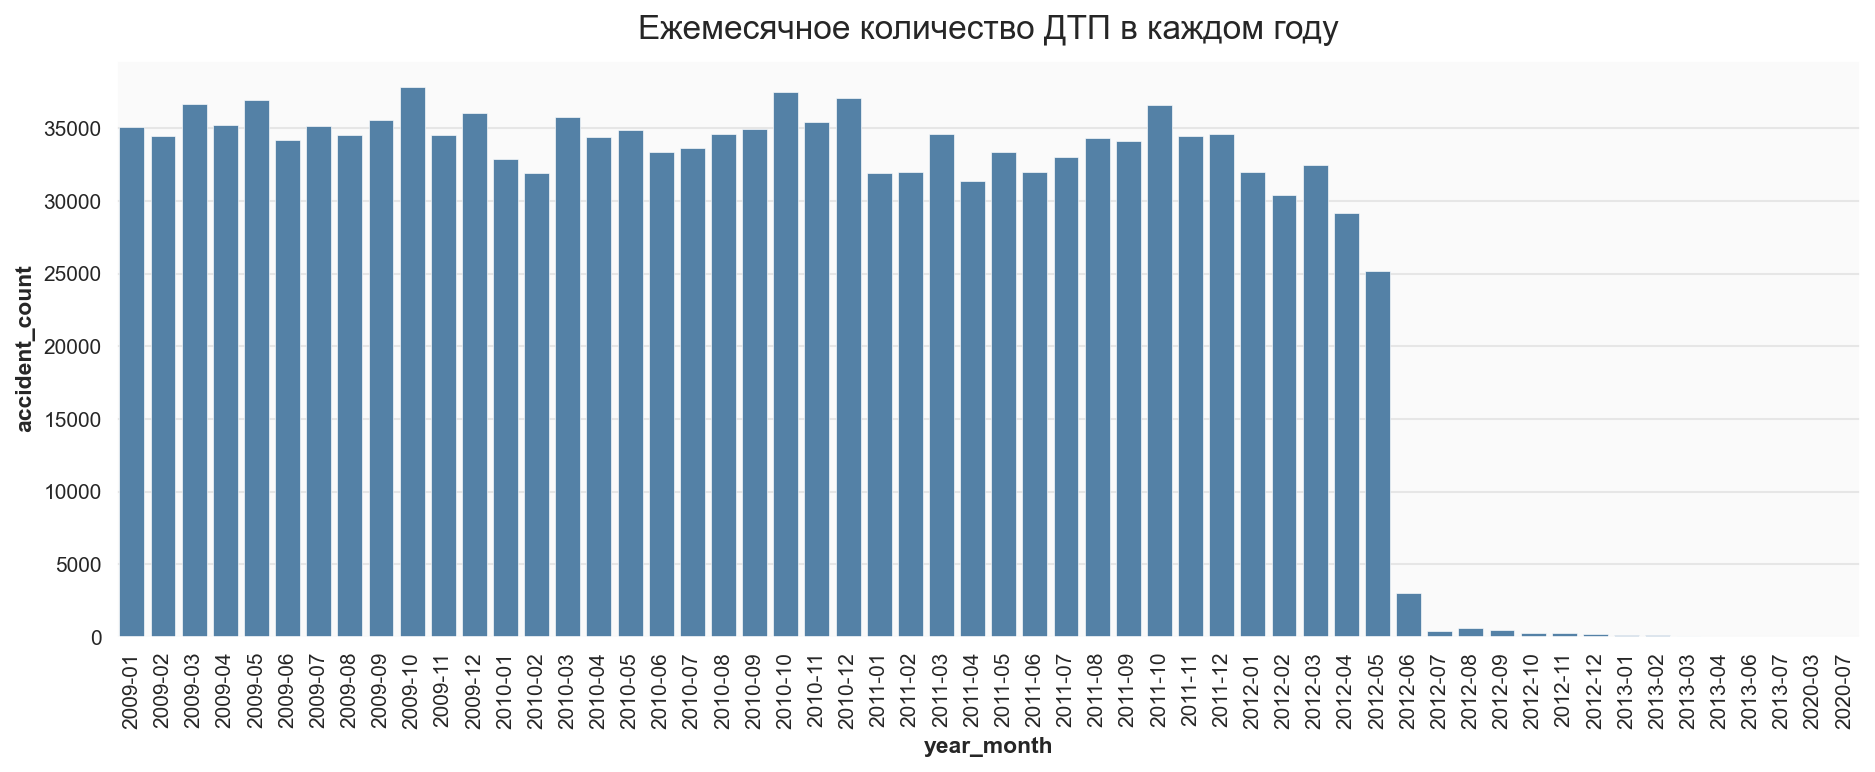

In [132]:
fig, ax = plt.subplots(figsize=(15,5), dpi=PLOT_DPI)
ax.set_title('Ежемесячное количество ДТП в каждом году')
sns.barplot(data=df, x='year_month', y='accident_count', color='steelblue')
plt.xticks(rotation=90);

> Судя по графику, нет значимой зависимости количества ДТП от месяца. Наблюдаемые колебания невелики и нестабильны.

> Примерно с апреля-июня 2012 года данные становятся неполными.  
> Это может внести искажение в результаты анализа ДТП в зависимости от месяца.

#### Общее количество ДТП в каждом месяце

In [133]:
query = '''
        SELECT
            CAST(EXTRACT(MONTH from collision_date) AS INTEGER) AS month,
            COUNT(case_id) AS accident_count
        FROM
            collisions
        GROUP BY
            EXTRACT(MONTH from collision_date)
        '''

df = sql_query(query)

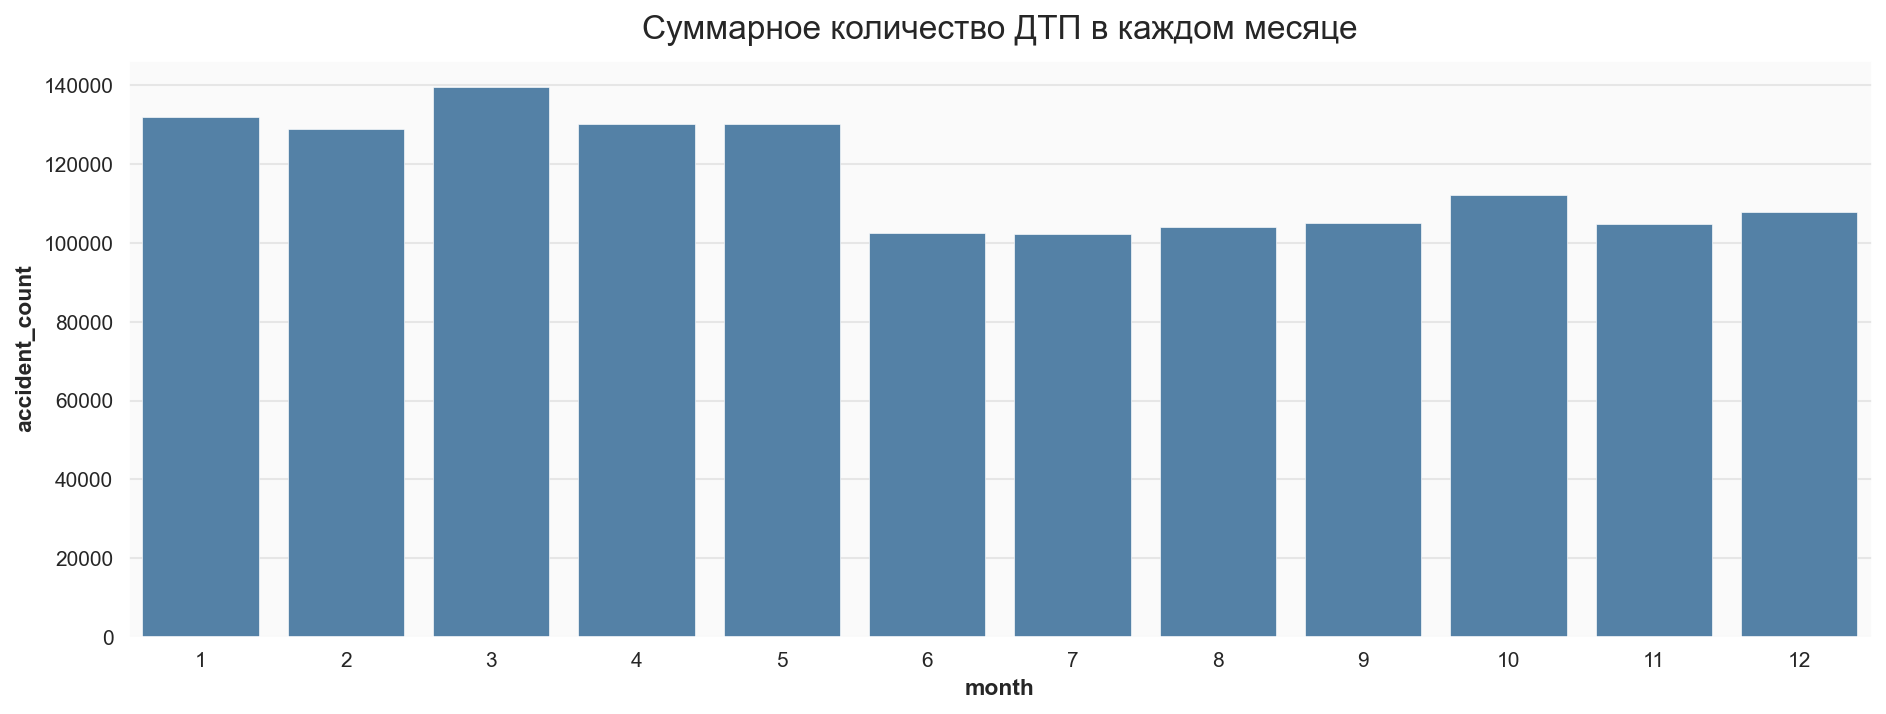

In [134]:
fig, ax = plt.subplots(figsize=(15,5), dpi=PLOT_DPI)
ax.set_title('Суммарное количество ДТП в каждом месяце')
sns.barplot(data=df, x='month', y='accident_count', color='steelblue');

> Отсутствие данных за часть рассматриваемого периода внесло искажение в анализ количества ДТП по месяцам.
> 
> Для более корректного анализа необходимо изменить границы анализируемого периода.

### Задачи для рабочей группы

1. Зависимость серьезности повреждений от освещенности дороги.
1. Динамика количества ДТП для разных регионов.
1. Зависимость количества участников ДТП от основного фактора аварии.
1. Доля неподвижных участников ДТП (дорожных объектов) в зависимости от типа места ДТП.
1. Зависимость количества участников ДТП от категории нарушения.
1. Зависимость типа аварии от возраста автомобиля.
1. Влияние типа местности на тип аварии.
1. Исследовать связь трех факторов: вид нарушения, количество участников, серьезность повреждений.
1. Доля виновников ДТП среди всех участников ДТП в зависимости от наличия перекрестка с разбивкой на интервалы длиной в 1 час.

<div class="alert alert-block alert-info">
Ниже добавил решение двух задач.
</div>

### Примеры решения

#### Средняя страховая премия в зависимости от возраста автомобиля

Использовать только данные для автомобилей, отфильтровать по `car` .  
Ограничить максимальный возраст автомобиля 30-ю годами.  
Построить график с разбивкой по типу автомобиля.

In [135]:
query = '''
        SELECT
            vehicle_type,
            vehicle_age,
            AVG(insurance_premium) AS insurance_premium_avg
        FROM
            vehicles
            JOIN parties ON parties.case_id = vehicles.case_id  AND parties.party_number = vehicles.party_number
        WHERE
            vehicle_age <= 30
            AND
            parties.party_type = 'car'
        GROUP BY
            vehicle_type,
            vehicle_age
        '''

df = load_data('task_1', query=query)

task_1 in process...
Memory usage before optimization: 0.001 MB
Memory usage after optimization: 0.001 MB
Memory usage reduced about 42%
task_1 successfully loaded from local storage



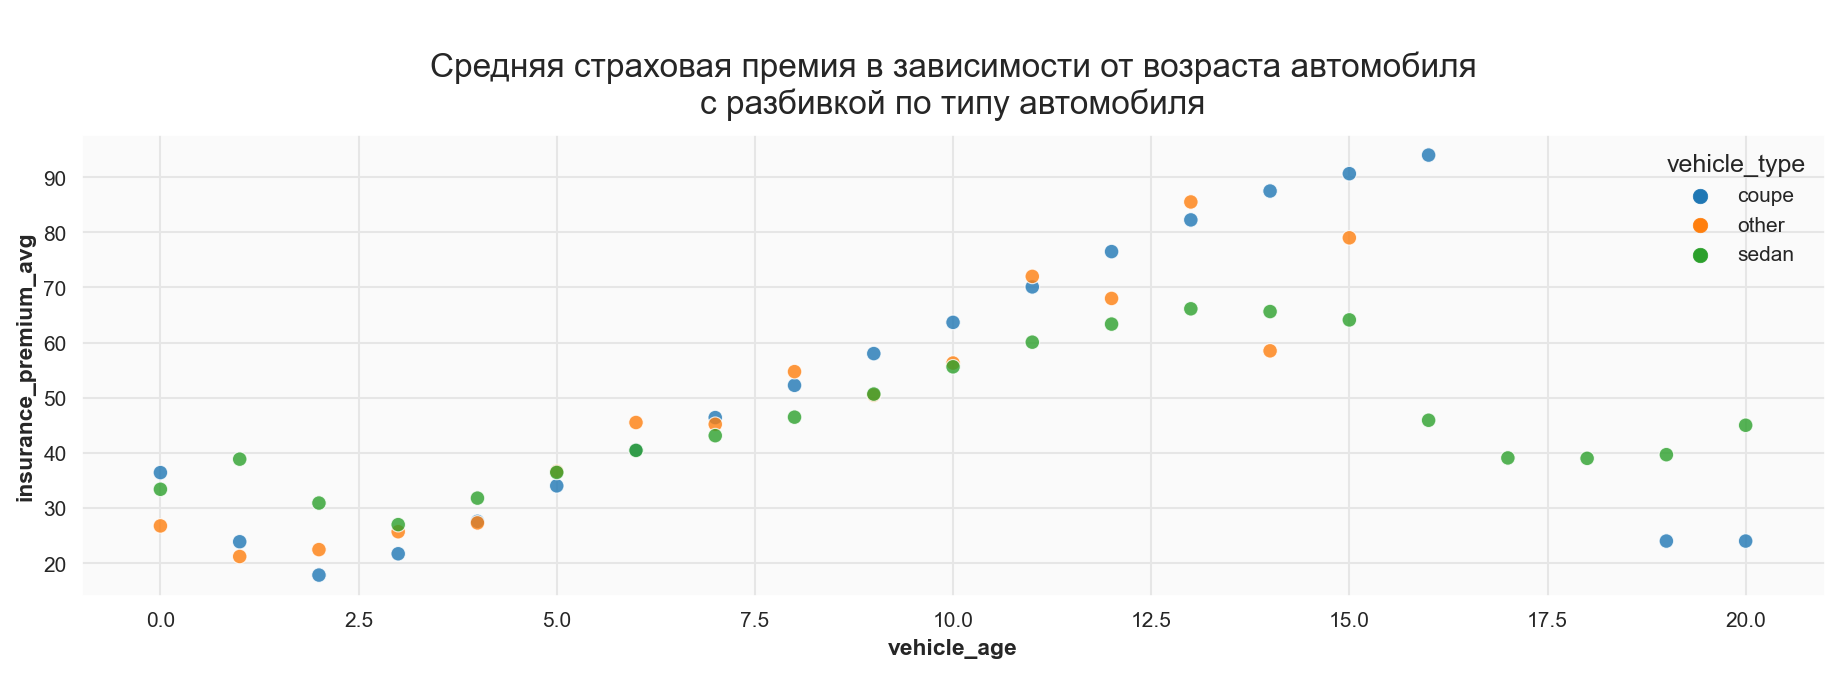

In [136]:
fig, ax = plt.subplots(figsize=(15,4), dpi=PLOT_DPI)
sns.scatterplot(data=df, x='vehicle_age', y='insurance_premium_avg', hue='vehicle_type', alpha=0.8, palette='tab10')
ax.set_title(f'{CR}Средняя страховая премия в зависимости от возраста автомобиля\nс разбивкой по типу автомобиля');

> Для автомобилей до 3-х лет нет однозначной тенденции `insurance_premium`.
>
> Начиная с 3-х лет, видна четко выраженная тенденция к росту `insurance_premium`.
>
> Для разных типов автомобилей зависимость имеет отличия:
> - для седанов стоимость премии постепенно меняет направление и идет на спад;
> - для купе стоимость все время растет (аномально низкие значения в конце выглядят как выбросы и требуют дополнительного изучения);
> - тип `other` имеет больший разброс и требует детализации для понимания.

#### Степень повреждений в зависимости от трезвости виновника ДТП

Взять данные только для виновников ДТП.  
Отфильтровать по типу `car`.

In [137]:
query = '''
        SELECT
            collision_damage,
            party_sobriety,
            COUNT(id) AS party_count
        FROM
            collisions
            JOIN parties ON parties.case_id = collisions.case_id
        WHERE
            party_type = 'car'
            AND
            at_fault = 1
        GROUP BY
            collision_damage,
            party_sobriety
        '''

df = load_data('task_2', query=query)

task_2 in process...
Memory usage before optimization: 0.001 MB
Memory usage after optimization: 0.001 MB
Memory usage reduced about 14%
task_2 successfully loaded from local storage



In [138]:
# сортировка категорий для облегчения анализа

sobriety_order = ['impairment unknown',
                  'not applicable',
                  'had not been drinking',
                  'had been drinking, not under influence',
                  'had been drinking, impairment unknown',
                  'had been drinking, under influence',
                 ]

damage_order = ['scratch',
                'small damage',
                'middle damage',
                'severe damage',
                'fatal',
               ]

df.party_sobriety = pd.Categorical(df.party_sobriety, categories=sobriety_order)
df.collision_damage = pd.Categorical(df.collision_damage, categories=damage_order)

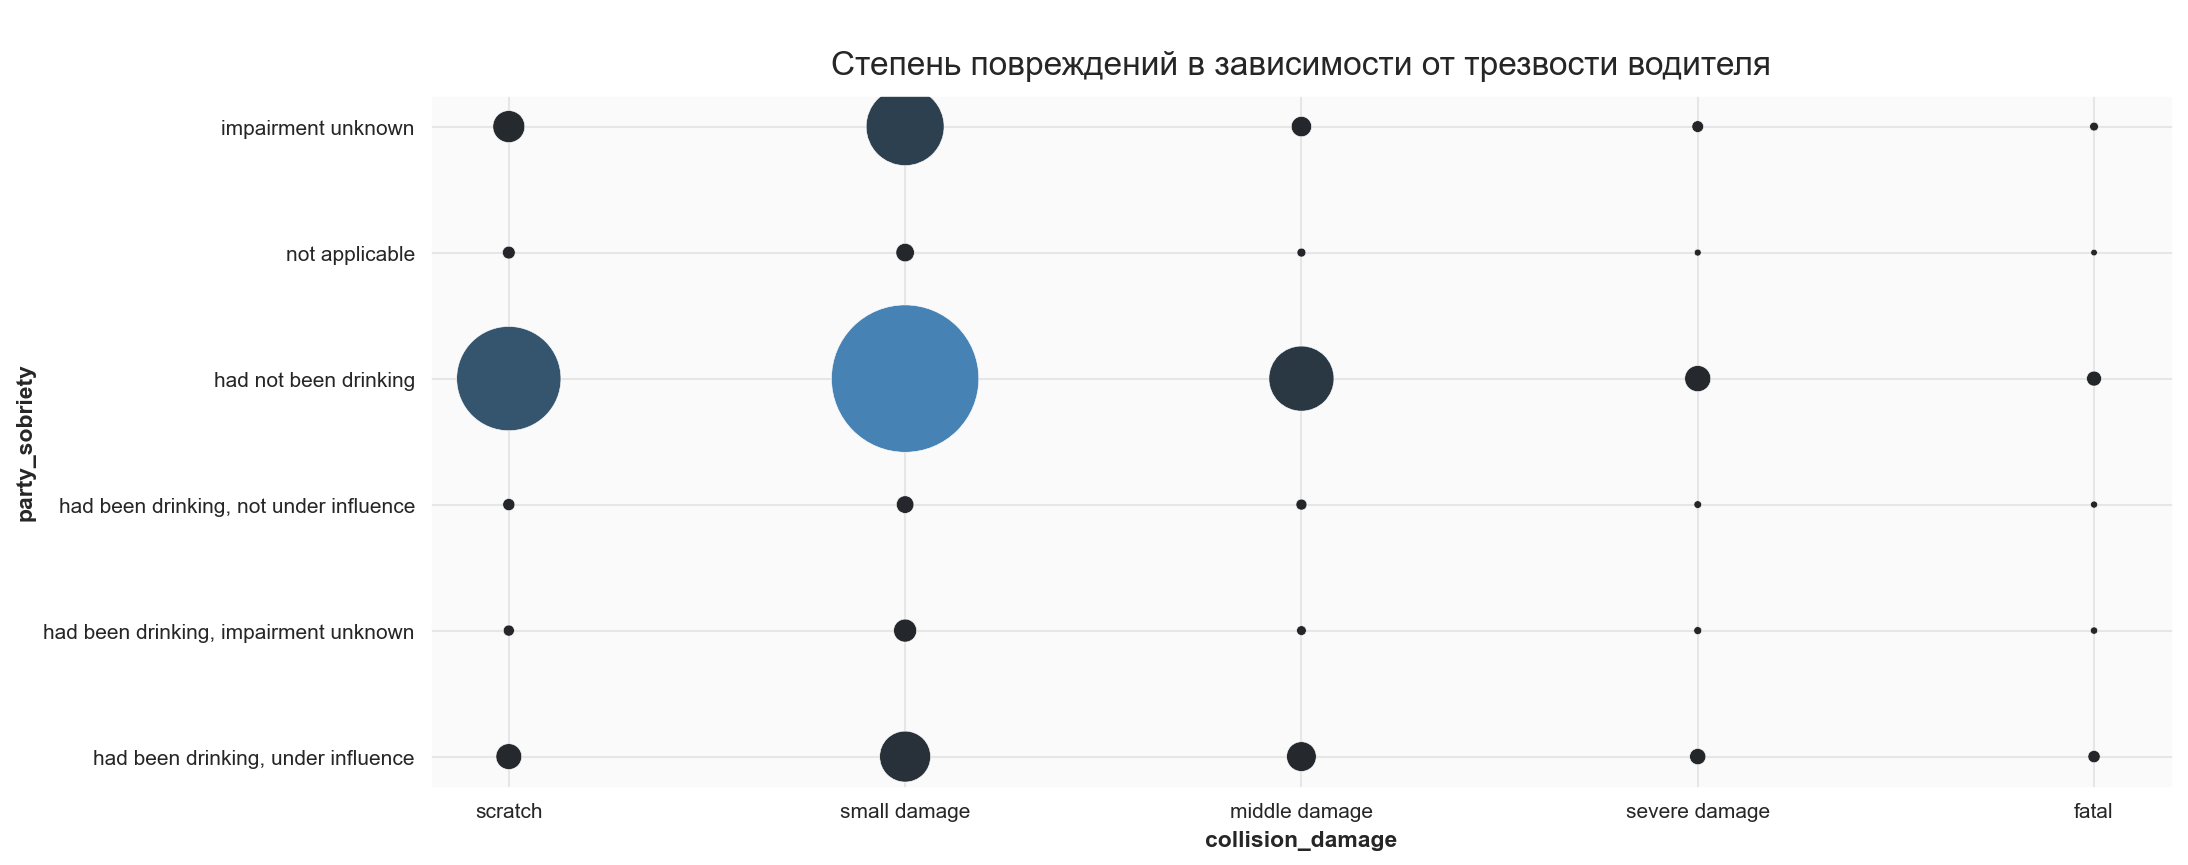

In [139]:
fig, ax = plt.subplots(figsize=(15,6), dpi=PLOT_DPI)
sns.scatterplot(data=df, x='collision_damage', y='party_sobriety', size='party_count', sizes=(10, 5000),
                legend=False, hue='party_count', palette=sns.color_palette("dark:steelblue", as_cmap=True))
ax.set_title(f'{CR}Степень повреждений в зависимости от трезвости водителя');

> График подтвердил, что большинство аварий заканчиваются незначительными повреждениями, а виновники были трезвыми.  
> Выявить связь степени повреждений со степенью трезвости виновника ДТП не удалось.

In [140]:
query = '''
        SELECT
            collision_damage,
            party_sobriety
        FROM
            collisions
            JOIN parties ON parties.case_id = collisions.case_id
        WHERE
            party_type = 'car'
            AND
            at_fault = 1
        '''

df = load_data('task_2a', query=query)

task_2a in process...
Memory usage before optimization: 18.926 MB
Memory usage after optimization: 18.926 MB
Memory usage reduced about 0%
task_2a successfully loaded from local storage



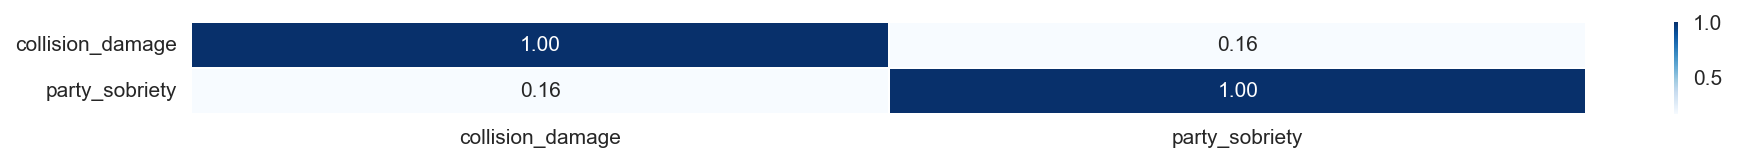

In [141]:
df_phik = df.phik_matrix()

fig, ax = plt.subplots(figsize=(15, 0.4*df.shape[1]), dpi=PLOT_DPI)
sns.heatmap(df_phik, annot=True, fmt='.2f', linewidths=0.2, annot_kws={'fontsize':10}, cmap='Blues')
plt.show()

> Чтобы подтвердить предыдущий вывод загружены неагрегированные данные и проверена корреляция с помощью библиотеки Phik.  
> Вывод подтвердился: корреляция между степенью трезвости виновника и тяжестью повреждений очень слабая.

---

## Подготовка данных для модели

### Загрузка данных

<div class="alert alert-block alert-info">
Исправил. Добавил связь по party_number.
</div>

In [142]:
query = '''
        SELECT
            collisions.*,
            parties.party_number,
            parties.party_type,
            parties.at_fault,
            parties.insurance_premium,
            parties.party_sobriety,
            parties.party_drug_physical,
            parties.cellphone_in_use,
            vehicles.vehicle_type,
            vehicles.vehicle_transmission,
            vehicles.vehicle_age
        FROM
            collisions
            JOIN parties ON parties.case_id = collisions.case_id
            JOIN vehicles ON vehicles.case_id = parties.case_id AND vehicles.party_number = parties.party_number
        WHERE
            parties.party_type = 'car'
            AND
            collisions.collision_damage != 'scratch'
            AND
            EXTRACT(YEAR FROM collisions.collision_date) = 2012
        ORDER BY
            collision_date,
            collision_time
        '''

data = load_data('data', query=query)

data in process...
Memory usage before optimization: 12.874 MB
Memory usage after optimization: 10.139 MB
Memory usage reduced about 21%
data successfully loaded from local storage



In [143]:
data.shape

(56248, 30)

In [144]:
basic_info(data)



 data ≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋≋


--- method info() ---

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 56248 entries, 0 to 56247
Data columns (total 30 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   case_id                      56248 non-null  int32  
 1   county_city_location         56248 non-null  int16  
 2   county_location              56248 non-null  object 
 3   distance                     56248 non-null  float32
 4   direction                    43230 non-null  object 
 5   intersection                 56073 non-null  float32
 6   weather_1                    56080 non-null  object 
 7   location_type                25932 non-null  object 
 8   collision_damage             56248 non-null  object 
 9   party_count                  56248 non-null  int8   
 10  primary_collision_factor     56137 non-null  object 
 11  pcf_violation_category       55482 non-null  object 
 12  type_of_co

,case_id,county_city_location,county_location,distance,direction,intersection,weather_1,location_type,collision_damage,party_count,primary_collision_factor,pcf_violation_category,type_of_collision,motor_vehicle_involved_with,road_surface,road_condition_1,lighting,control_device,collision_date,collision_time,party_number,party_type,at_fault,insurance_premium,party_sobriety,party_drug_physical,cellphone_in_use,vehicle_type,vehicle_transmission,vehicle_age
14941,5510686,1942,los angeles,200.000,south,0.000,clear,highway,middle damage,2,vehicle code violation,speeding,rear end,other motor vehicle,dry,normal,daylight,none,2012-02-12,15:03:00,2,car,1,46.000,had not been drinking,NaN,0.000,coupe,auto,6.000
37562,5586019,1941,los angeles,240.000,north,0.000,clear,NaN,middle damage,2,unknown,unknown,broadside,other motor vehicle,dry,normal,daylight,none,2012-04-14,14:21:00,1,car,0,44.000,had not been drinking,NaN,0.000,coupe,manual,7.000
5066,5506030,3000,orange,600.000,east,0.000,raining,highway,middle damage,1,vehicle code violation,speeding,overturned,fixed object,wet,normal,dark with no street lights,none,2012-01-15,20:30:00,1,car,1,34.000,"had been drinking, not under influence",NaN,0.000,coupe,manual,5.000
20905,5514267,1942,los angeles,124.000,east,0.000,clear,NaN,middle damage,2,vehicle code violation,unsafe lane change,sideswipe,other motor vehicle,dry,normal,daylight,none,2012-02-29,11:50:00,1,car,0,48.000,had not been drinking,NaN,0.000,coupe,manual,7.000
30293,5553337,1942,los angeles,1275.000,north,0.000,cloudy,highway,small damage,2,vehicle code violation,speeding,broadside,other motor vehicle,wet,normal,daylight,none,2012-03-25,12:00:00,1,car,1,53.000,had not been drinking,NaN,0.000,sedan,auto,3.000




--- method describe(all) ---


,case_id,county_city_location,distance,intersection,party_count,party_number,at_fault,insurance_premium,cellphone_in_use,vehicle_age
count,56248.000,56248.000,56248.000,56073.000,56248.000,56248.000,56248.000,55701.000,51777.000,54554.000
mean,5561566.907,2844.491,859.439,0.222,2.075,1.527,0.504,37.607,0.020,4.856
std,58762.456,1293.949,7240.295,0.415,0.798,0.663,0.500,16.329,0.141,3.235
min,5125160.000,100.000,0.000,0.000,1.000,1.000,0.000,0.000,0.000,0.000
25%,5514720.250,1942.000,7.000,0.000,2.000,1.000,0.000,24.000,0.000,3.000
50%,5558989.000,3009.000,135.000,0.000,2.000,1.000,1.000,34.000,0.000,4.000
75%,5613234.000,3701.000,545.000,0.000,2.000,2.000,1.000,49.000,0.000,7.000
max,5668356.000,5802.000,1584000.000,1.000,10.000,9.000,1.000,105.000,1.000,161.000


,count,unique,top,freq
county_location,56248,58,los angeles,16236
direction,43230,4,north,12129
weather_1,56080,7,clear,45092
location_type,25932,3,highway,21323
collision_damage,56248,4,small damage,30551
primary_collision_factor,56137,5,vehicle code violation,53915
pcf_violation_category,55482,22,speeding,18241
type_of_collision,55940,7,rear end,18766
motor_vehicle_involved_with,56086,9,other motor vehicle,41200
road_surface,55900,4,dry,50242


### Первичный отбор признаков для модели

Строим модель для определения, виноват ли водитель определенного автомобиля в ДТП.  
Признаки будут отобраны для этой модели. При отборе будет оцениваться, мог ли определенный фактор увеличить/уменьшить вероятность вины водителя. Для этого можно вообразить долю виновных водителей (отношение количества виновников ДТП к общему количеству участников ДТП).

In [145]:
cols = [
#       'case_id',                       # нет: уникальный идентификатор
#       'county_city_location',          # нет: слишком много (496) категорий
        'county_location',               # слабый: в разных регионах может различаться доля виновных водителей.
        'distance',                      # слабый: возможно, выше доля ДТП с одним водителем либо, наоборот, массовых ДТП
        'direction',                     # слабый: например, солнце, светящее в глаза
#       'intersection',                  # нет: дублирует признак location_type
        'weather_1',                     # слабый: ниже доля виновных водителей за счет более массовых ДТП
        'location_type',                 # средний: возможно, на шоссе чаще случаются одиночные ДТП (выше доля виновников)
        'collision_damage',              # слабый: вряд ли по степени повреждений можно определить виновника ДТП
        'party_count',                   # сильный: чем меньше участников ДТП, тем выше доля виновников
        'primary_collision_factor',      # средний: может влиять на количество участников ДТП
        'pcf_violation_category',        # средний: странно, что данный фактор не отнесен к конкретному участнику ДТП
        'type_of_collision',             # средний: может влиять на количество участников ДТП
        'motor_vehicle_involved_with',   # сильный: влиять на количество участников ДТП
        'road_surface',                  # средний: может влиять на количество участников ДТП
        'road_condition_1',              # средний: может влиять на количество участников ДТП
        'lighting',                      # средний: может влиять на количество участников ДТП
        'control_device',                # ??? : вообще неясно, что за нёх, поэтому проще проверить
        'collision_date',                # слабый: можно поискать зависимость от месяца или рабочего/выходного дня
        'collision_time',                # средний: в разное время суток количество участников ДТП должно различаться
#       'party_number',                  # нет: фактически, это уникальный идентификатор для участников ДТП
#       'party_type',                    # нет: в отобранных данных все значения = 'car'
        'at_fault',                      # !!! : целевой признак
        'insurance_premium',             # сильный: может указывать на потенциальную склонность водителя к нарушениям
        'party_sobriety',                # сильный: прямо указывает на возможность неадекватного поведения водителя
        'party_drug_physical',           # сильный: прямо указывает на возможность неадекватного поведения водителя
#       'cellphone_in_use',              # нет: большой дисбаланс и много пропусков
        'vehicle_type',                  # средний: возможно, есть связь между типом автомобиля и нарушениями, ведущими к ДТП
        'vehicle_transmission',          # слабый: влияние оценить трудно, но лучше проверить, чем гадать
        'vehicle_age',                   # слабый: влияние может быть противоположным, поэтому лучше проверить
       ]

In [146]:
data = data[cols]

### Небольшие улучшения данных

#### Дата и время

In [147]:
print(data.collision_time.isna().sum())

data = data.dropna(subset=['collision_time'])

data['collision_datetime'] = pd.to_datetime(data.collision_date.astype(str) + ' ' + data.collision_time.astype(str))

data = data.drop(['collision_date','collision_time'], axis=1)

88


> Поскольку количество пропусков в `collision_time` незначительно, пропуски удалены, а дата и время объединены в единое поле `collision_datetime`, из которого далее можно извлекать необходимые признаки.  
> Исходные поля с датой и временем удалены.

In [148]:
data['collision_month'] = data.collision_datetime.dt.month.astype('object')
data['collision_weekday'] = data.collision_datetime.dt.weekday.astype('object')
data['collision_hour'] = data.collision_datetime.dt.hour.astype('object')

data = data.drop('collision_datetime', axis=1)

> Из `collision_datetime` извлечены месяц, день недели и час, а сам исходный признак удален.

#### vehicle_age

In [149]:
data.loc[data.vehicle_age == 161, 'vehicle_age'] = 16

> В `vehicle_age` исправлены несколько предполагаемых опечаток.

## Исследование признаков

### Распределения признаков

#### Числовые признаки

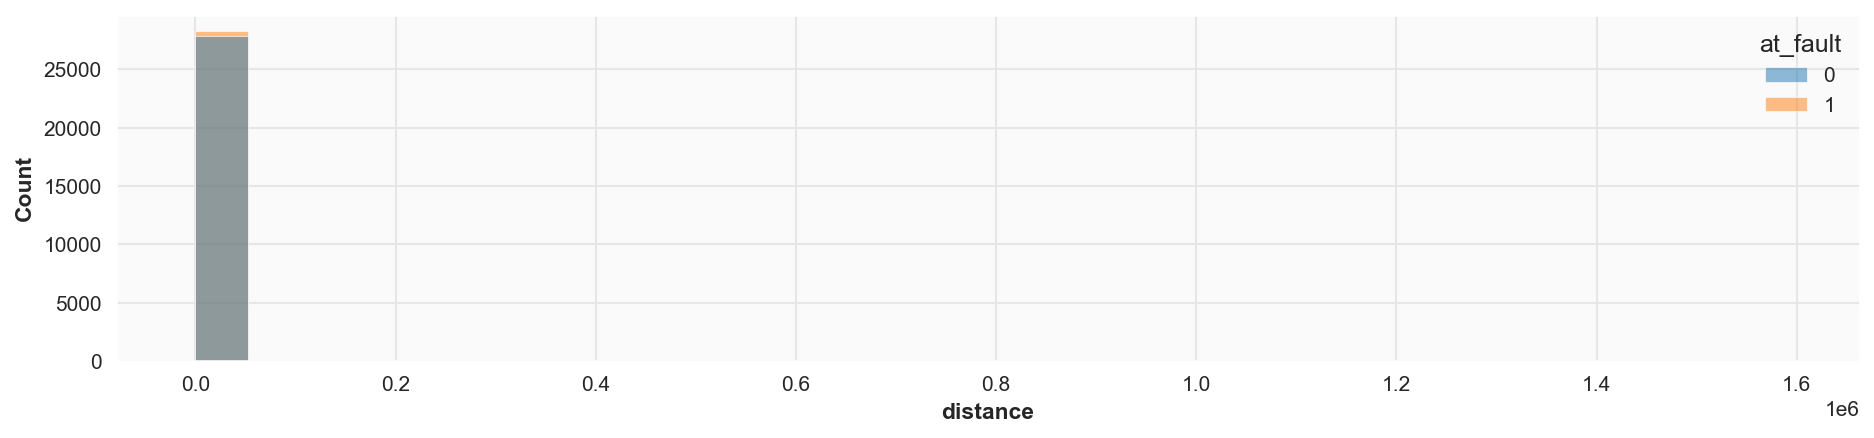

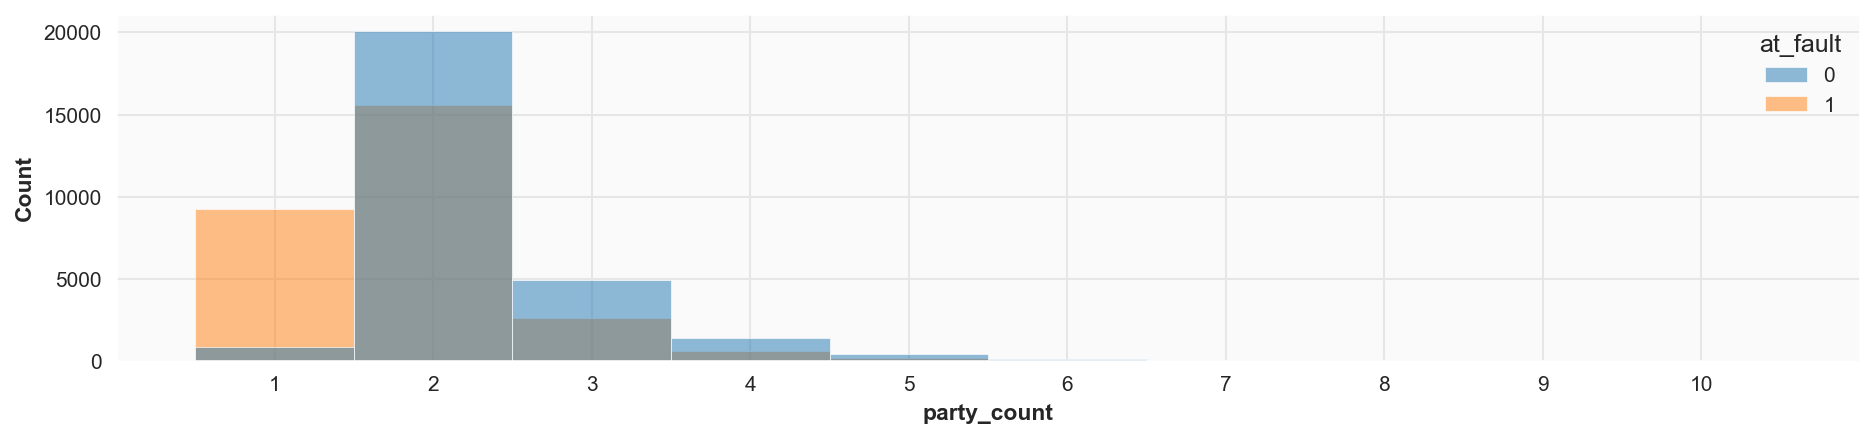

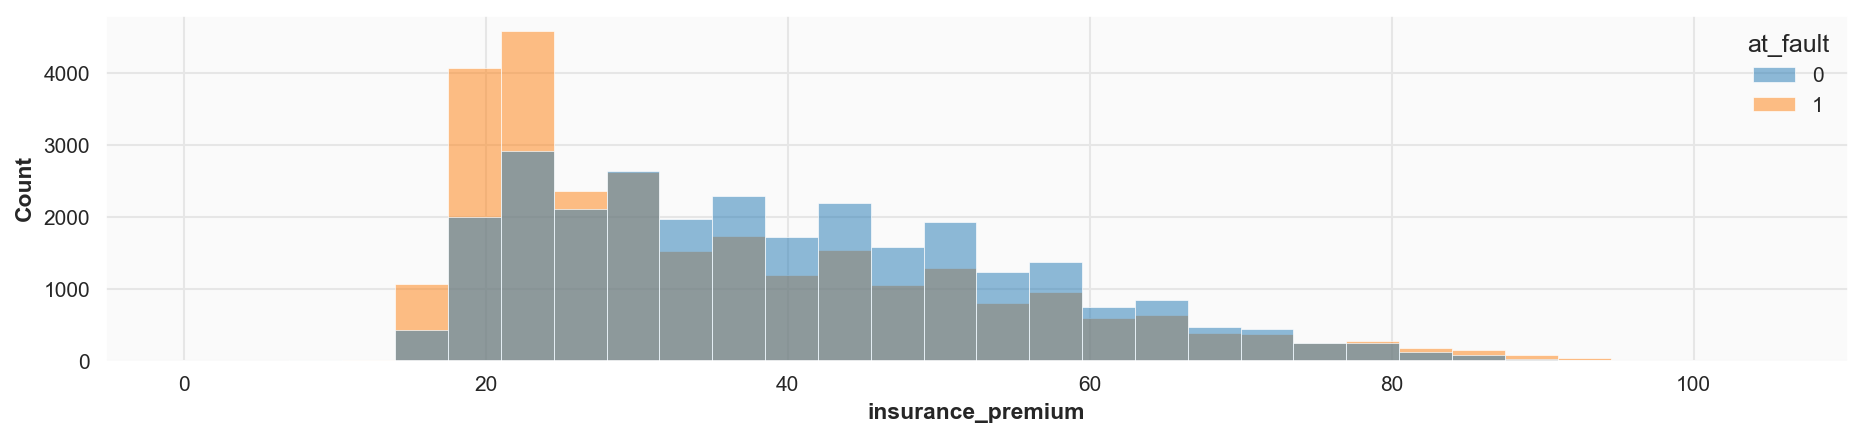

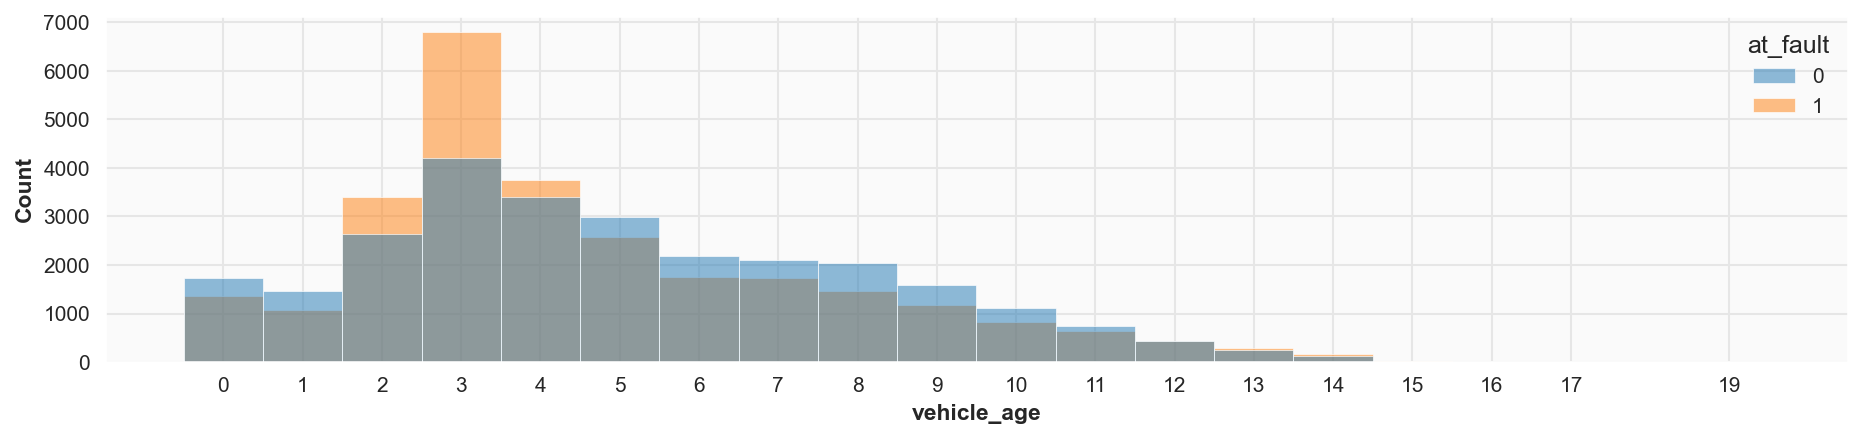

In [150]:
num_fields = data.drop(TARGET, axis=1).select_dtypes(include='number').columns.to_list()

for column in num_fields:

    # временный датафрейм содержит анализируемый и целевой признаки, NaN удаляются
    df = data[[column, TARGET]].dropna(subset=[column])
    
    # подбор количества корзин для лучшего представления
    bins_treshold = 30
    is_discrete = True if df[column].nunique() < bins_treshold else False
    
    fig, ax = plt.subplots(figsize=(15,3), dpi=PLOT_DPI)
    sns.histplot(x=df[column], hue=data[TARGET], bins=bins_treshold, discrete=is_discrete, palette='tab10')
    
    if df[column].nunique() < bins_treshold:
        ax.set_xticks(df[column].unique());

Для анализа распределения признака `distance` больше подходит нелинейная шкала, поэтому дополнительно построен график `log(distance)`.

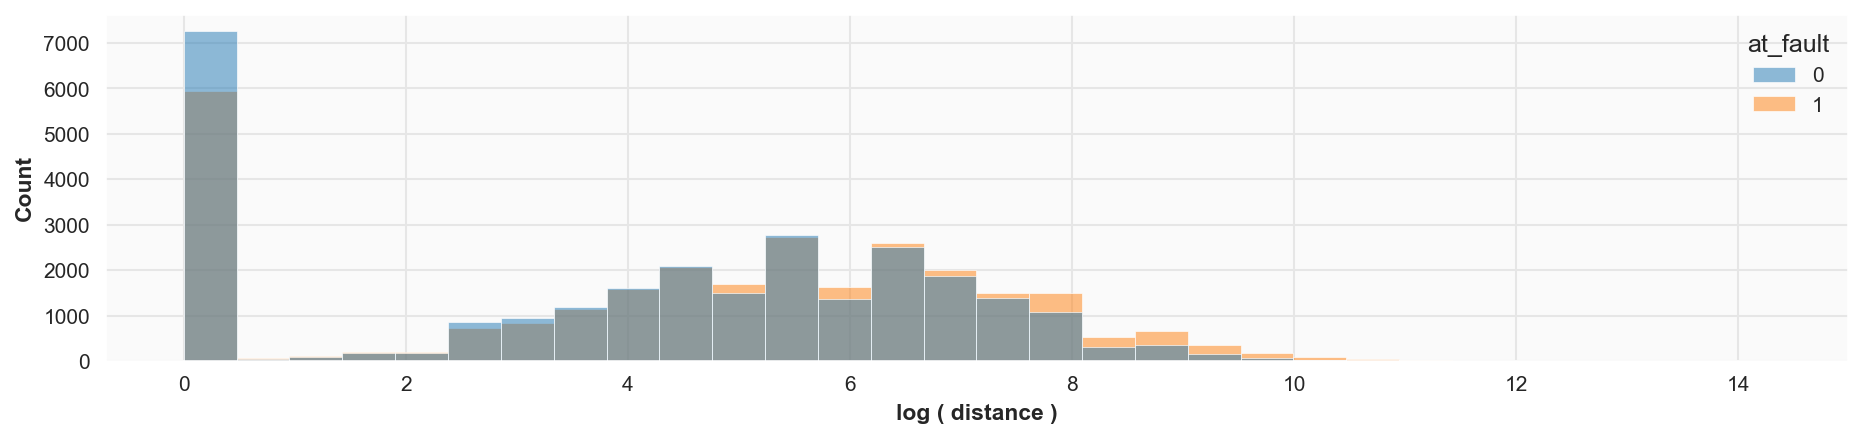

In [151]:
column = 'distance'

df = data[[column, TARGET]].dropna(subset=[column])

fig, ax = plt.subplots(figsize=(15,3), dpi=PLOT_DPI)
sns.histplot(x=np.log(df[column]+1), hue=data[TARGET], bins=bins_treshold, palette='tab10')
ax.set_xlabel('log ( distance )');

Почти тот же график, но без нулевых значений.

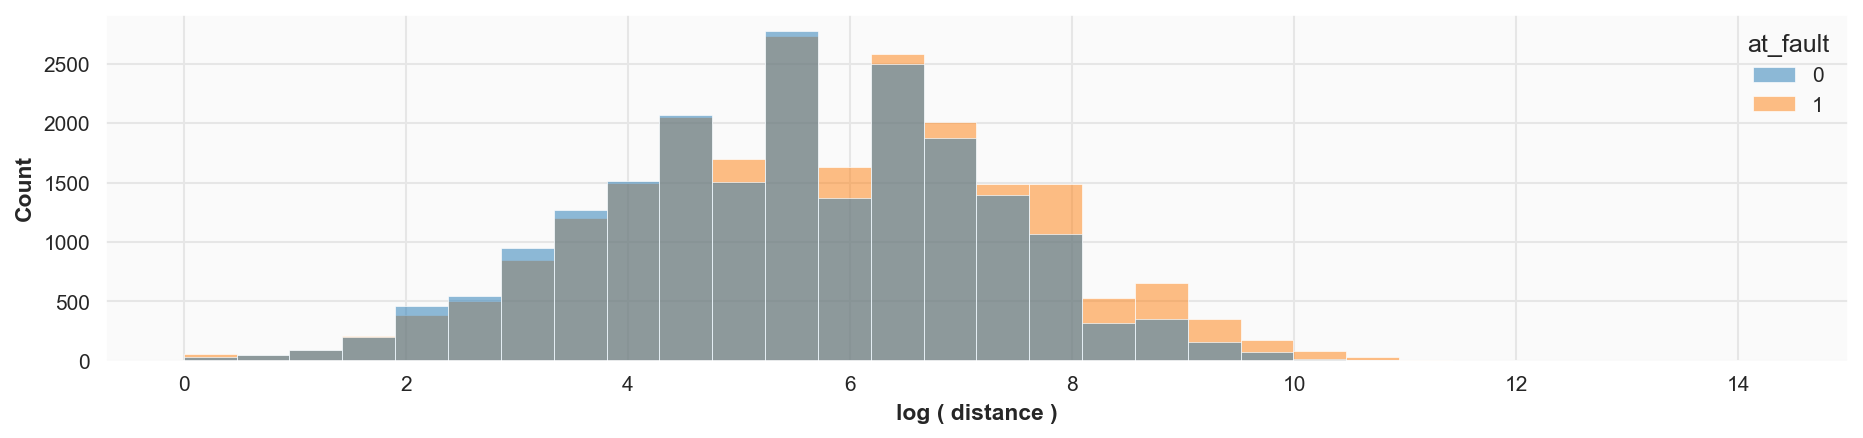

In [152]:
column = 'distance'

df = data[[column, TARGET]].dropna(subset=[column])

fig, ax = plt.subplots(figsize=(15,3), dpi=PLOT_DPI)
sns.histplot(x=np.log(df[column]), hue=data[TARGET], bins=bins_treshold, palette='tab10')
ax.set_xlabel('log ( distance )');

Для `insurance_premium` тоже применим логарифмирование.

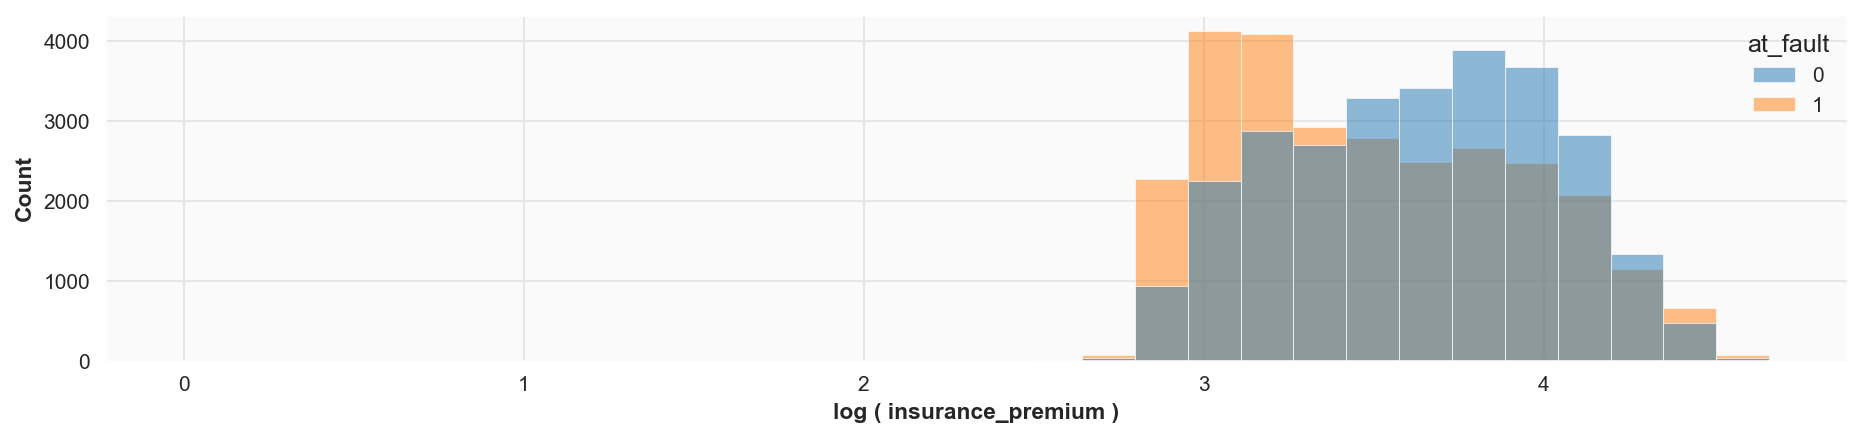

In [153]:
column = 'insurance_premium'

df = data[[column, TARGET]].dropna(subset=[column])

fig, ax = plt.subplots(figsize=(15,3), dpi=PLOT_DPI)
sns.histplot(x=np.log(df[column]+1), hue=data[TARGET], bins=bins_treshold, palette='tab10')
ax.set_xlabel('log ( insurance_premium )');

> Анализ графиков распределений числовых признаков.

> **distance**  
> Ввиду сильной скошенности `distance` необходимо его нелинейно преобразовать, чтобы что-то разглядеть. Например, логарифмировать. В начале и конце графика распределение несколько отличается от средней части.
>
> **party_count**  
> Чем больше участников ДТП, тем труднее выделить виновника. Внезапно! ))  
> Возможно, это — самый важный признак.
>
> **insurance_premium**  
> Распределение целевого признака напоминает `distance`. Логарифмирование `insurance_premium` помогает, по крайней мере, визуально.
>
> **vehicle_age**  
> Колебания незначительны и, вероятно, случайны. Можно было бы **исключить** этот признак, но(!) *заказчик настаивает, что это — обязательный фактор для модели*.
>
> **collision_month**  
> Колебания незначительны и, вероятно, случайны. Кроме того, половина данных отсутствует. Можно **исключить** этот признак.
>
> **collision_weekday**  
> Колебания незначительны и, вероятно, случайны. Есть небольшое отклонение в воскресенье, но вряд ли этого достаточно. Можно (пока) **исключить** этот признак.
>
> **collision_hour**  
> Видно существенное изменение распределения в ночные часы. Вероятно, это объясняется меньшим количеством автомобилей и, следовательно, меньшим количеством участников ДТП.

#### Категориальные признаки

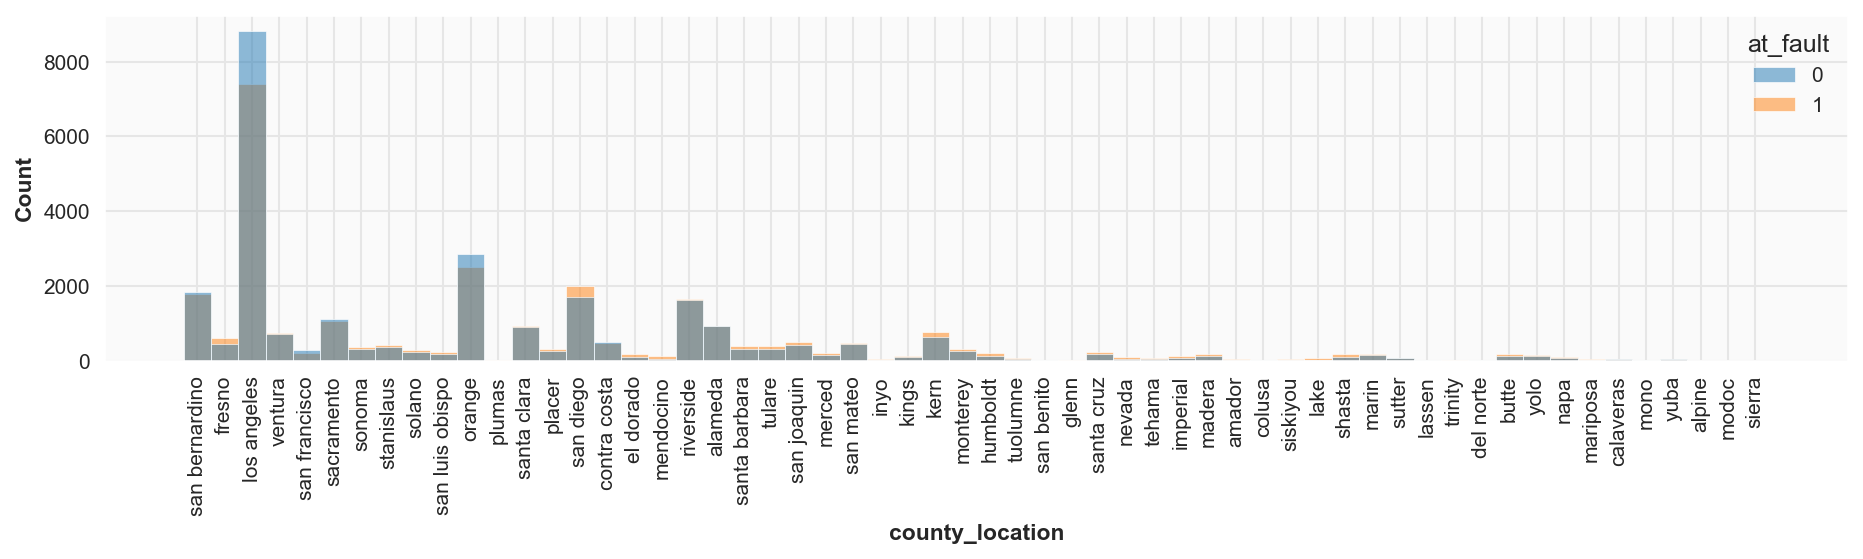

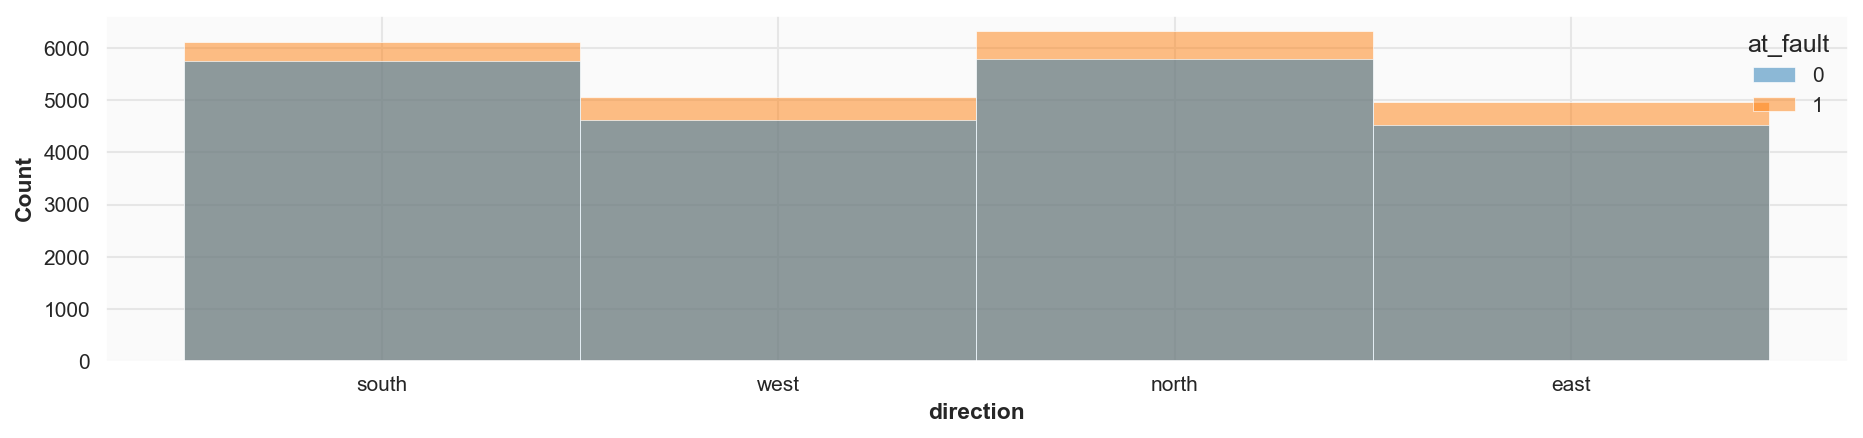

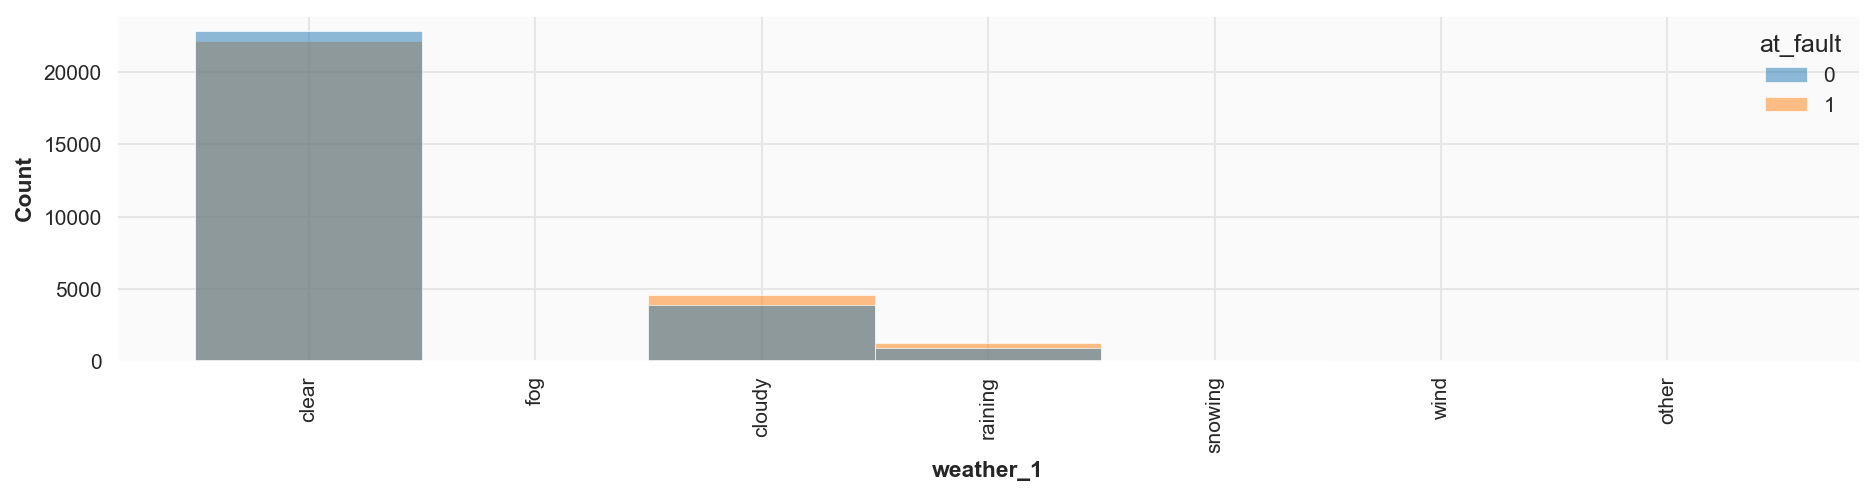

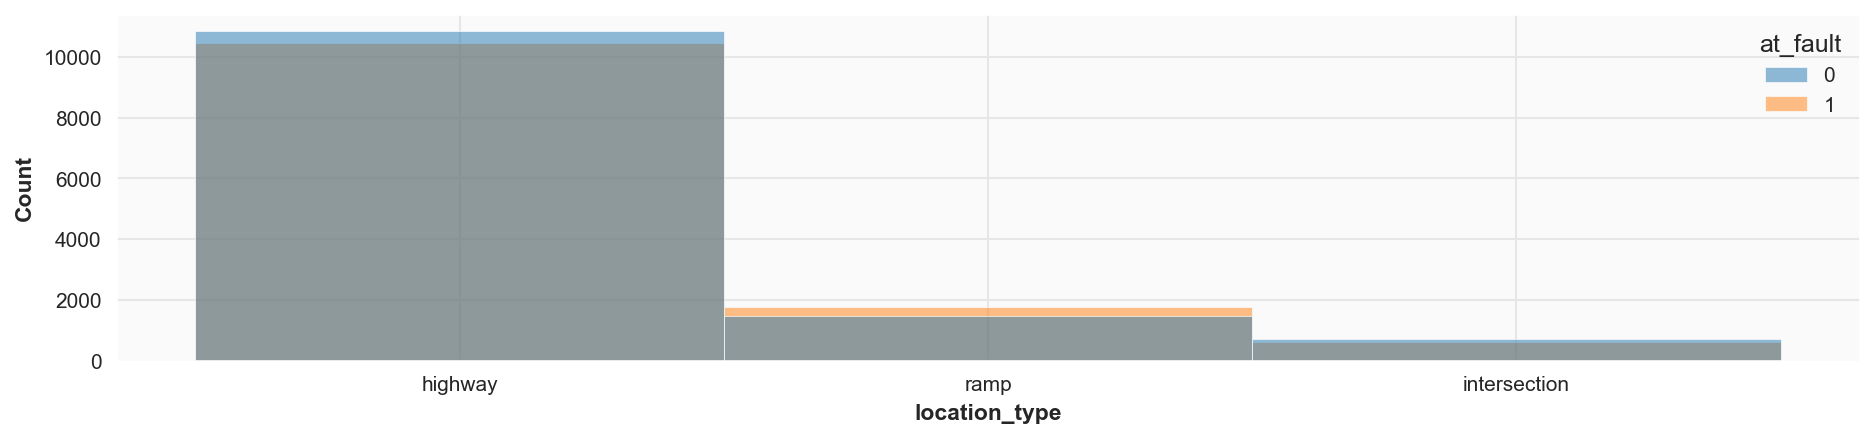

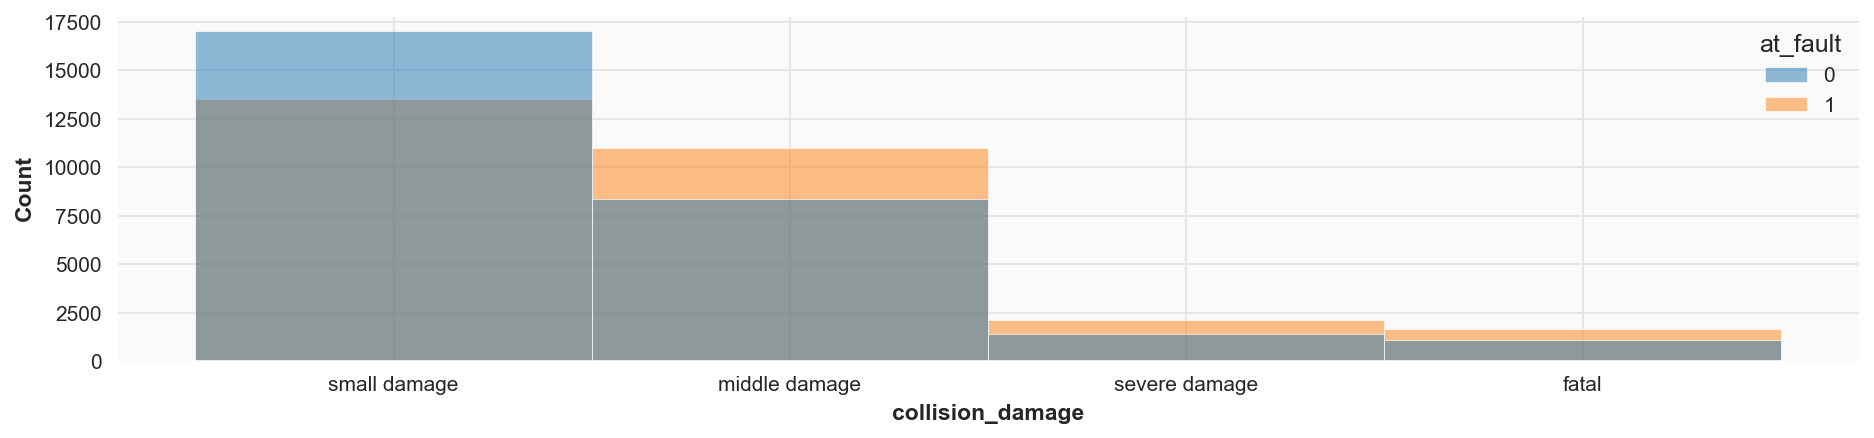

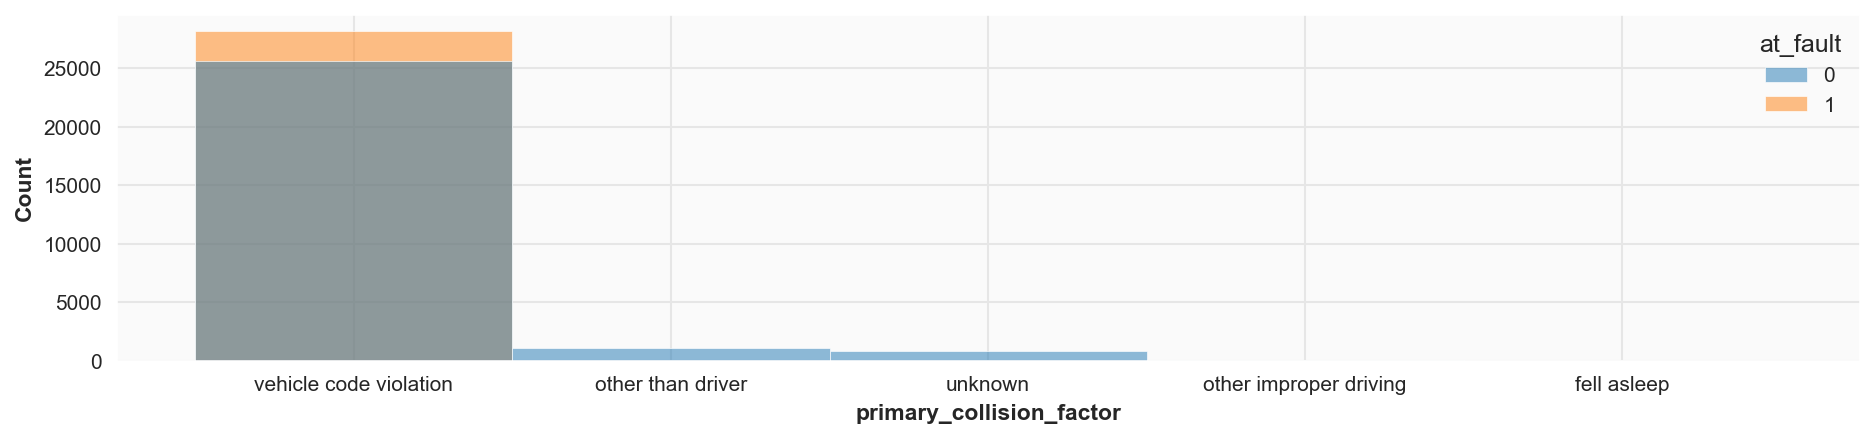

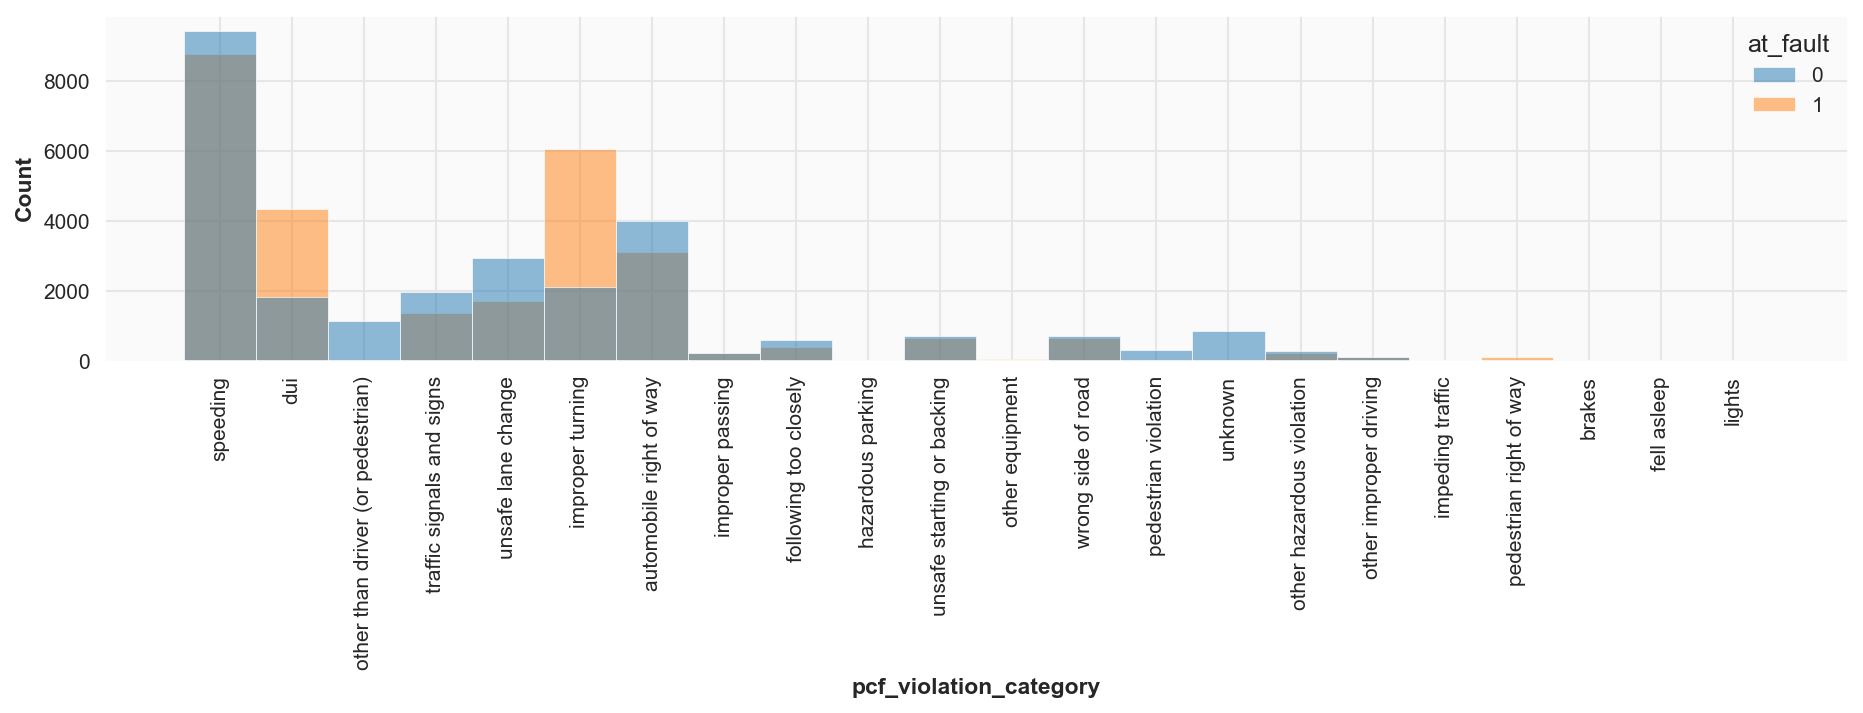

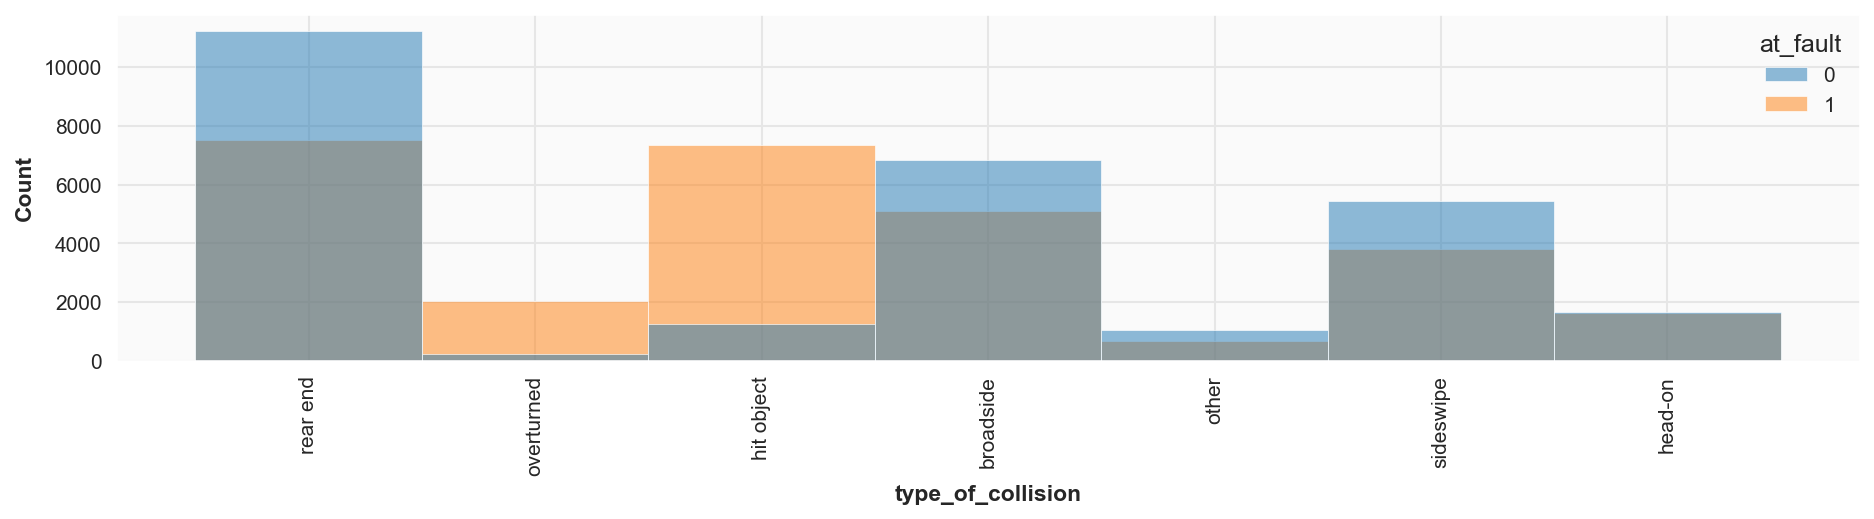

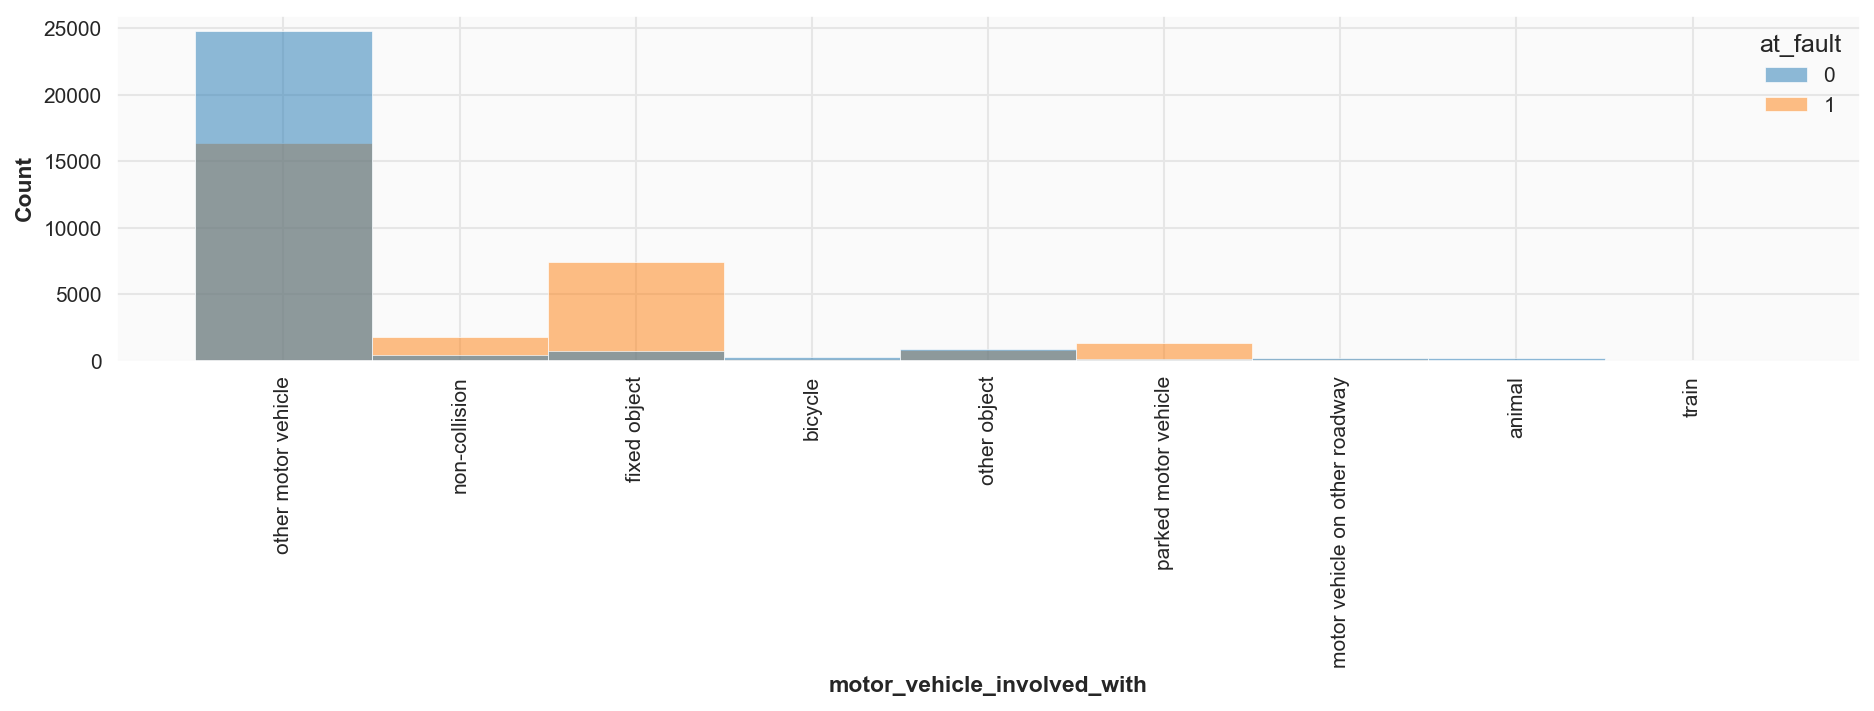

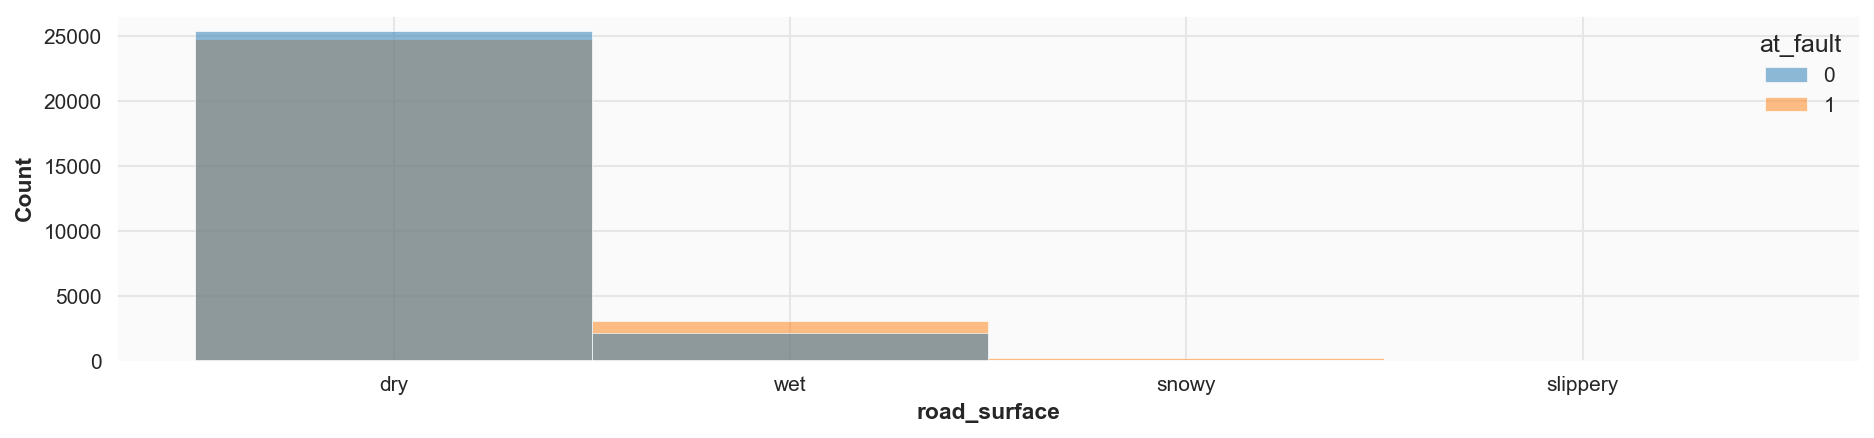

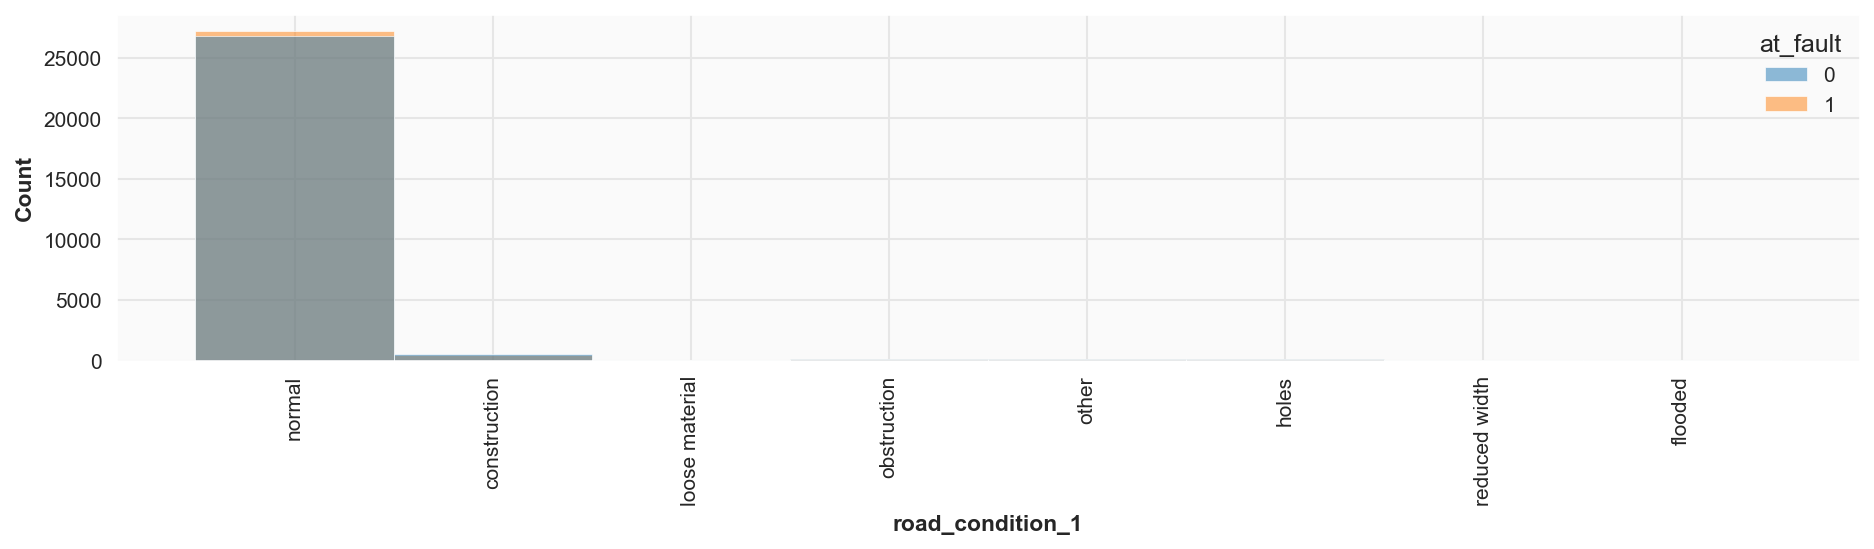

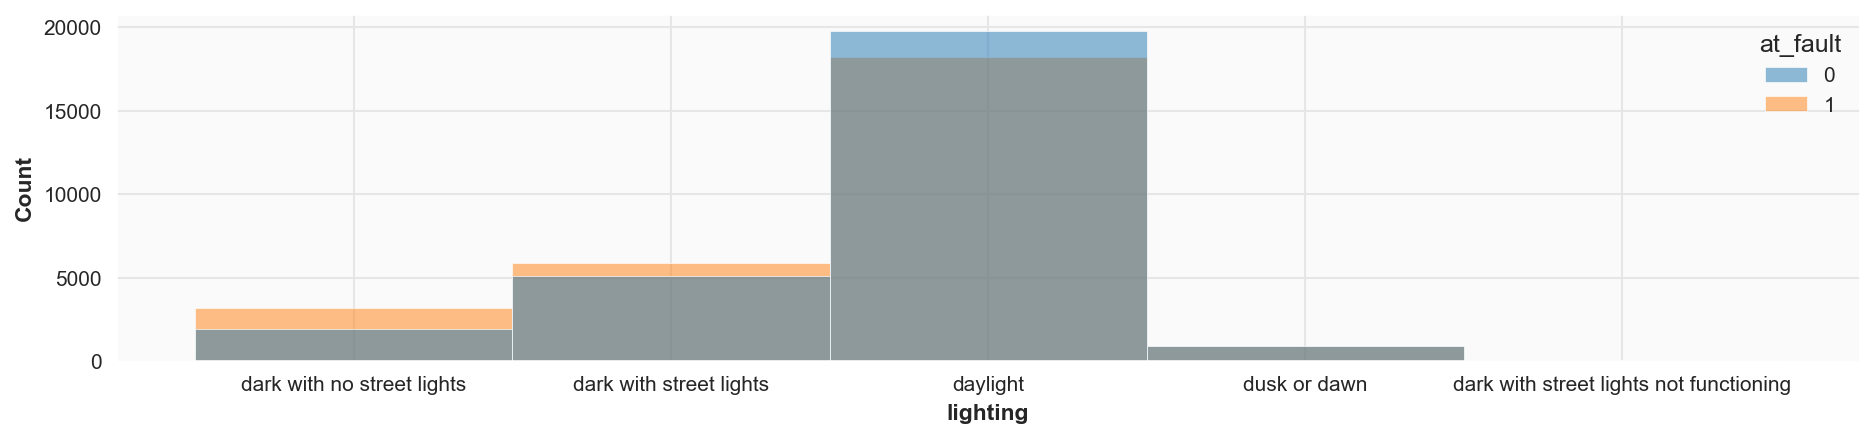

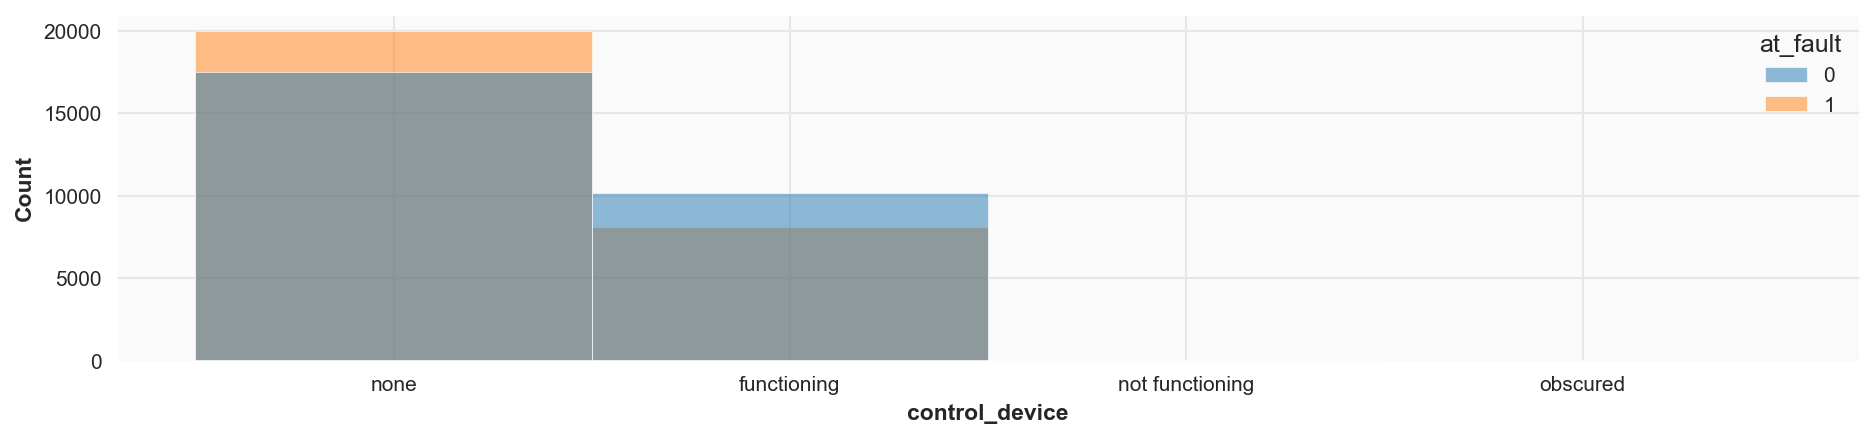

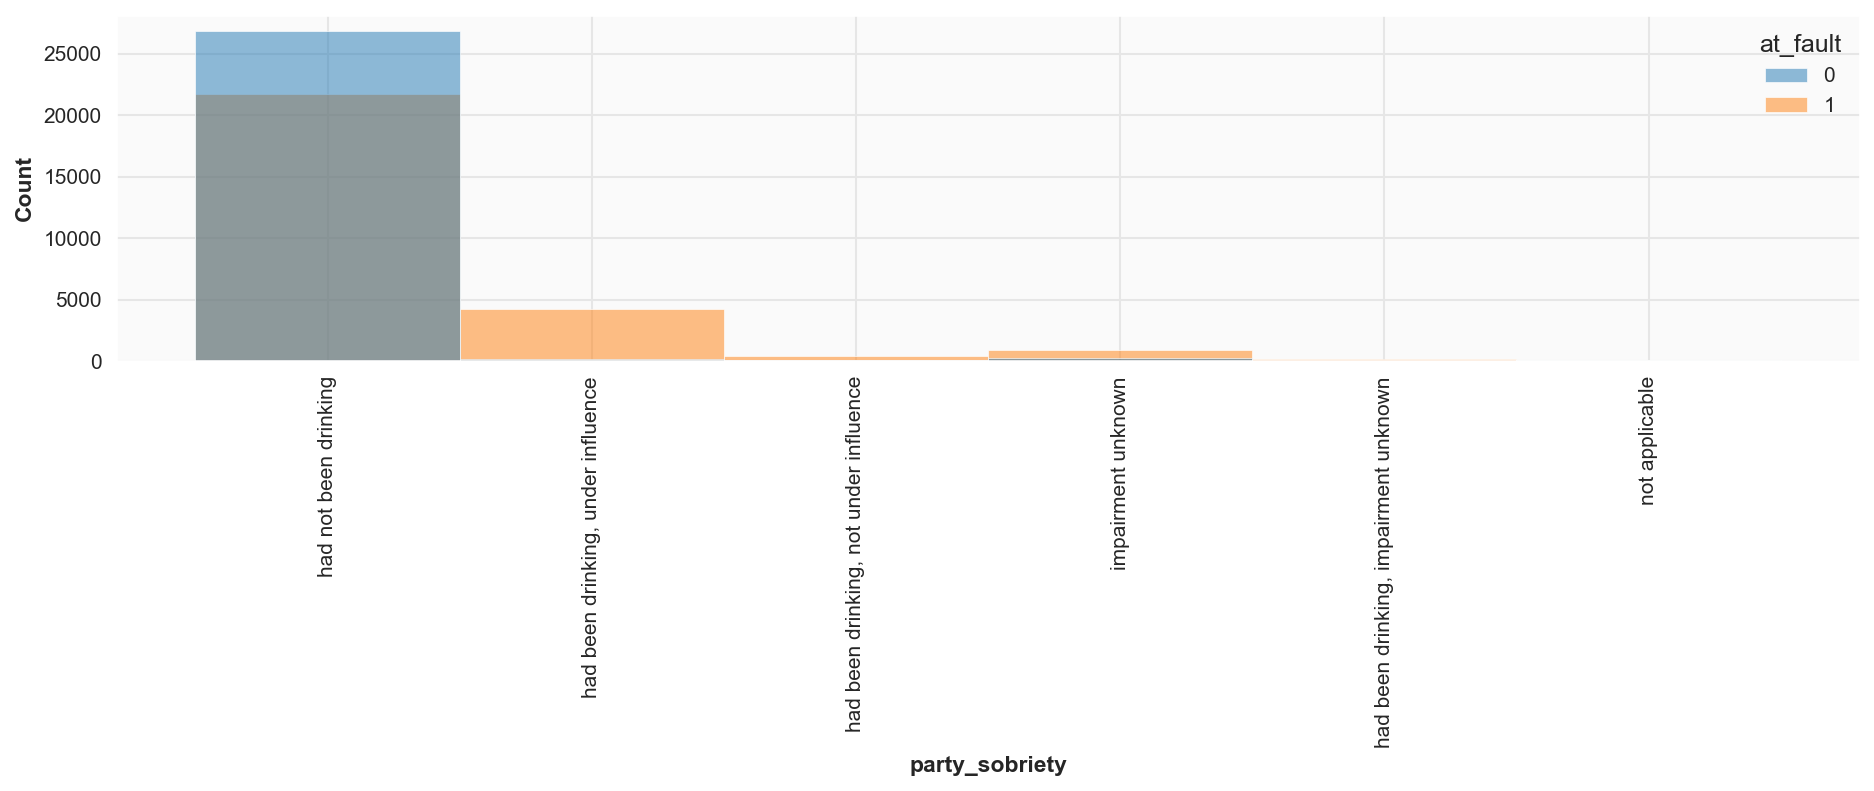

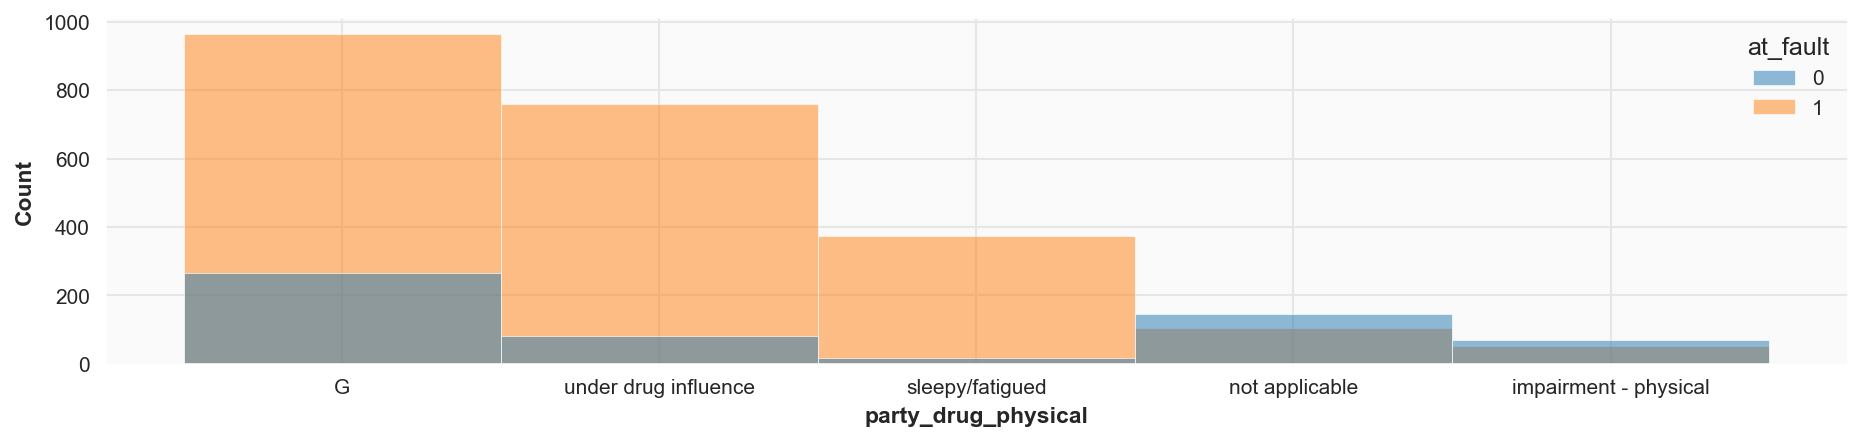

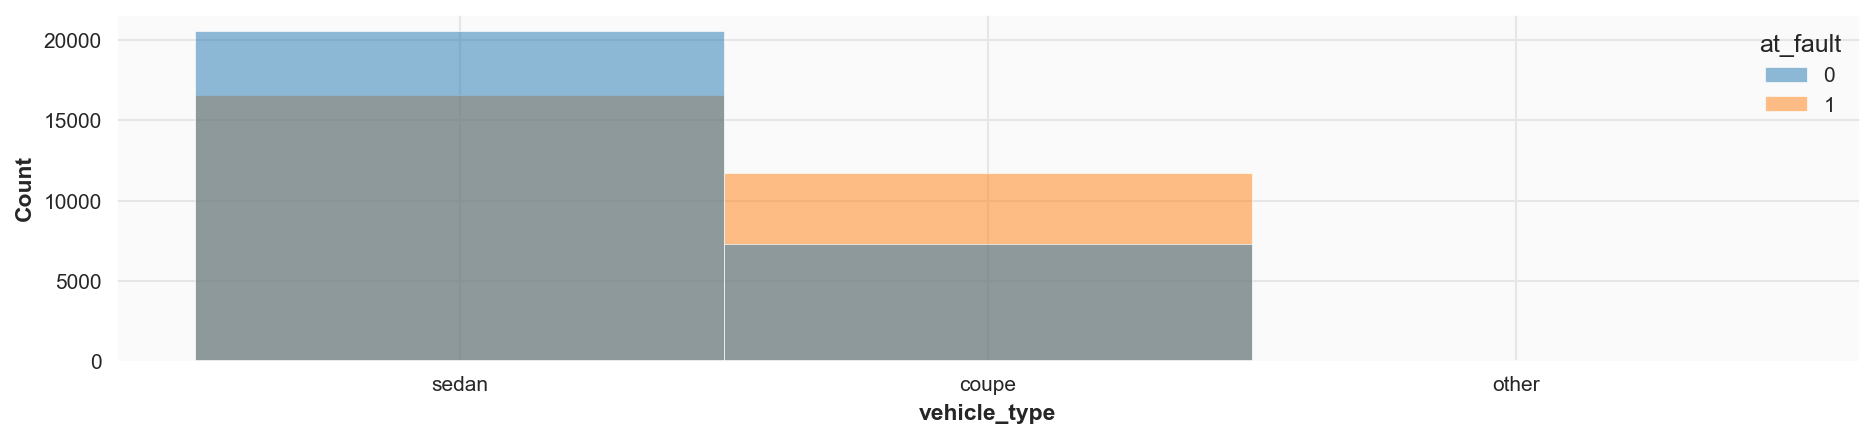

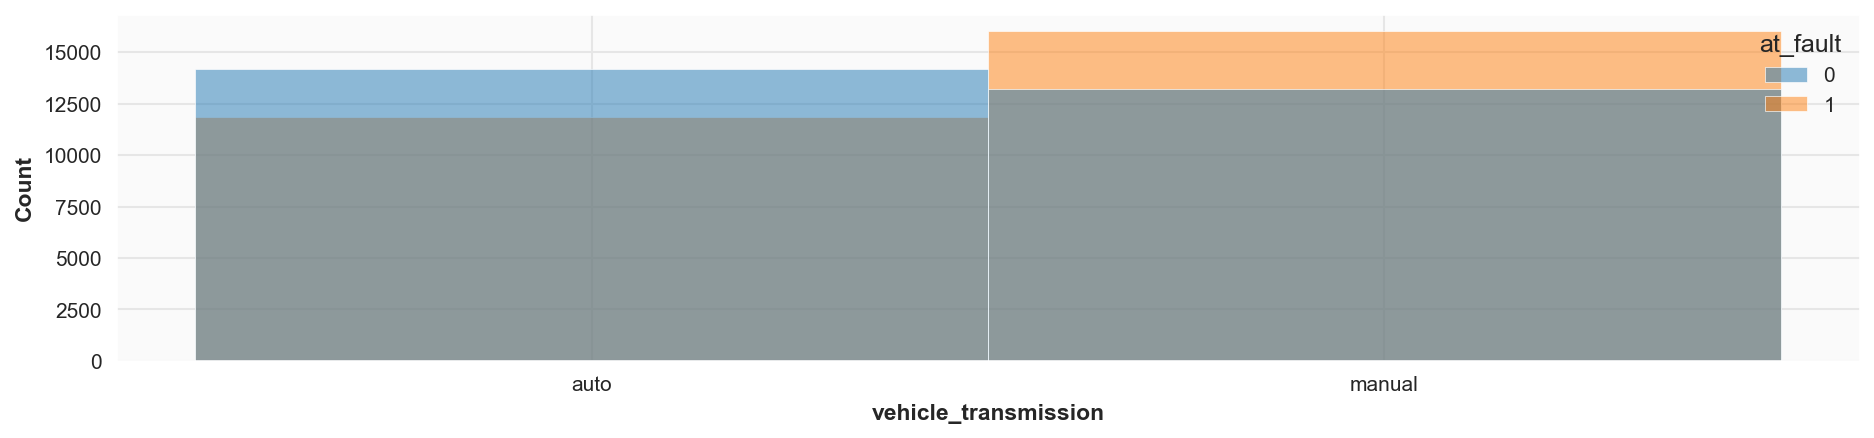

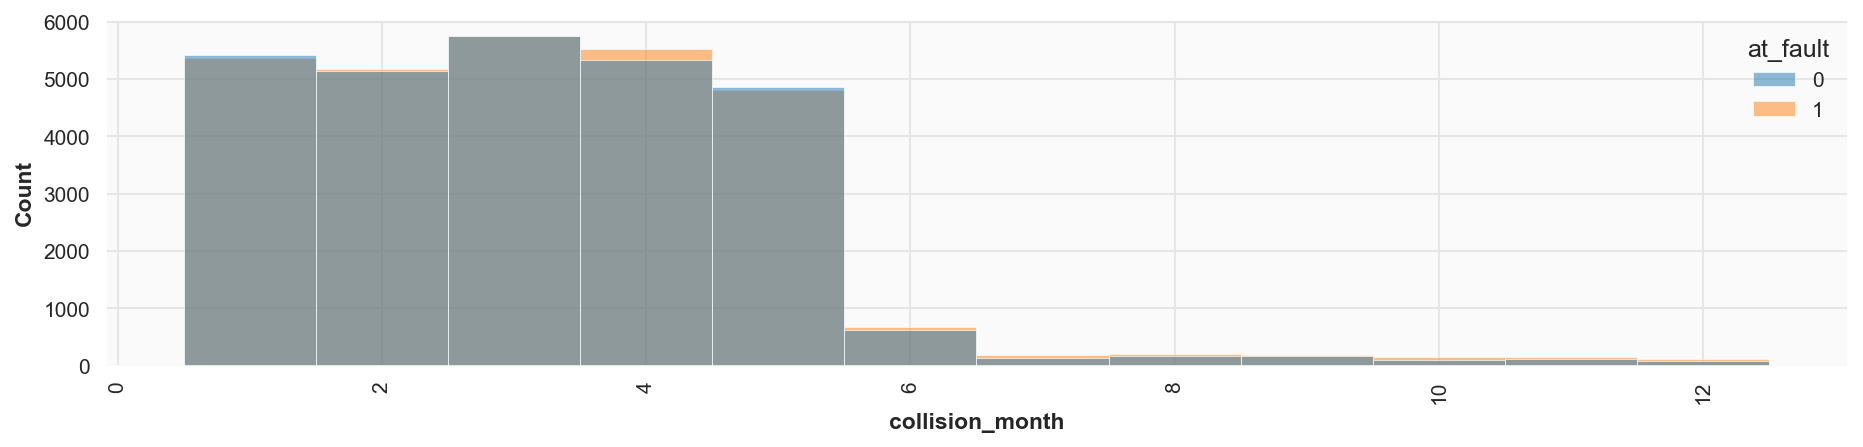

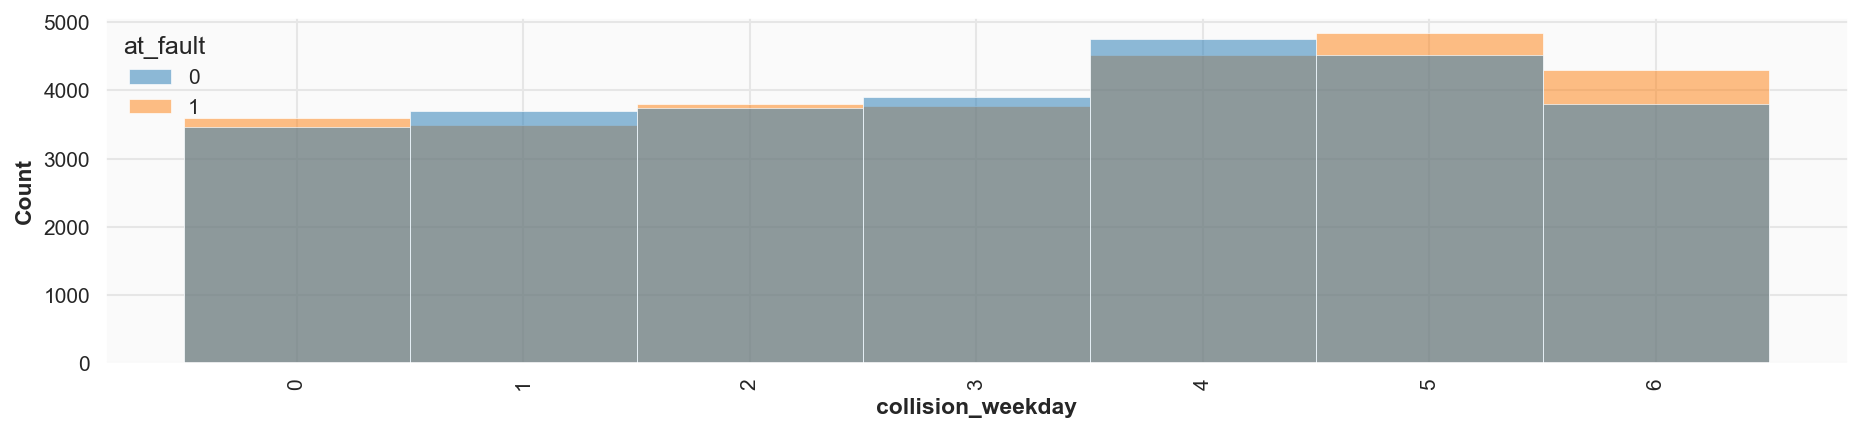

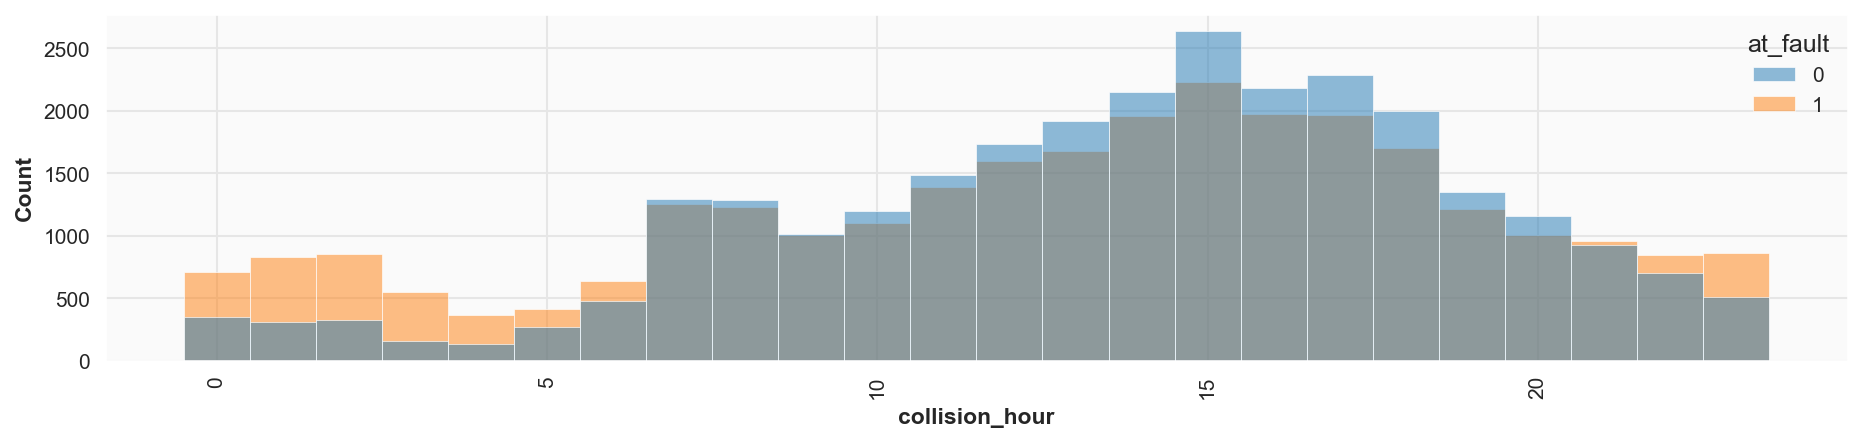

In [154]:
cat_fields = data.select_dtypes(exclude='number').columns.to_list()
df = data[cat_fields]

for column in df.columns:
    
    fig, ax = plt.subplots(figsize=(15,3), dpi=PLOT_DPI)
    sns.histplot(x=df[column], hue=data[TARGET], bins=bins_treshold, discrete=is_discrete, palette='tab10')
    
    if df[column].nunique() > 5:
        plt.xticks(rotation=90);

> Анализ графиков распределений категориальных признаков.

> **county_location**  
> Большая часть ДТП сосредоточена в нескольких регионах, что снижает роль различия между регионами. Колебания распределения целевого признака незначительны и, вероятно, учтены в других признаках. Можно (пока) **исключить** этот признак, но в дальнейшем добавить его в модель в качестве эксперимента.
> 
> **direction**  
> Колебания незначительны и, вероятно, случайны. Можно **исключить** этот признак.
>
> **weather_1**  
> Большая часть категорий не задействована. Для задействованных категорий есть небольшое различие, которое, вероятно, учтено в других признаках. Можно (пока) **исключить** этот признак, но в дальнейшем добавить его в модель в качестве эксперимента.
>
> **location_type**  
> Есть небольшое различие в распределении целевого признака. Признак содержит много пропусков. Можно **исключить**.
>
> **collision_damage**  
> Есть небольшое различие в распределении целевого признака.
>
> **primary_collision_factor**  
> Почти все значения сконцентрированы в одной категории, поэтому признак, скорее всего, бесполезен. Можно **исключить**.
>
> **pcf_violation_category**  
> Есть существенные различия распределения для разных категорий.
>
> **type_of_collision**  
> Есть существенные различия распределения для разных категорий.
>
> **motor_vehicle_involved_with**  
> Несмотря на то, что большая часть значений сосредоточена в одной категории, различие распределения между категориями существенно, чтобы им не пренебрегать.
>
> **road_surface**  
> Большая часть значений сосредоточена в одной категории, а различие в распределении невелико. Можно **исключить** этот признак.
>
> **road_condition_1**  
> Большая часть значений сосредоточена в одной категории, а различие в распределении невелико. Можно **исключить** этот признак.
>
> **lighting**  
> Есть небольшое различие в распределении целевого признака.
>
> **control_device**  
> Различия в распределении практически нет. Можно **исключить** этот признак.
>
> **party_sobriety**  
> Несмотря на то, что большая часть значений сосредоточена в одной категории, различие распределения между категориями существенно, чтобы им не пренебрегать.
>
> **party_drug_physical**  
> Большая часть значений отсутствует. Можно **исключить**.
>
> **vehicle_type**  
> Есть небольшое различие в распределении целевого признака.
>
> **vehicle_transmission**  
> Колебания незначительны и, вероятно, случайны. Можно **исключить** этот признак.

### Удаление малоперспективных признаков

In [155]:
drop_feature = [
#               'vehicle_age',                # оставлен по требованию заказчика
                'collision_month',
                'collision_weekday',
                'county_location',
                'direction',
                'weather_1',
                'location_type',
                'primary_collision_factor',
                'road_surface',
                'road_condition_1',
                'control_device',
                'party_drug_physical',
                'vehicle_transmission',
               ]

data = data.drop(drop_feature, axis=1)

### NaN

#### pcf_violation_category

In [156]:
# заполнение пропусков
data.pcf_violation_category = data.pcf_violation_category.fillna('unknown')

# подсчет относительной частоты значений
counts = data.pcf_violation_category.value_counts(normalize=True)

# замена значений, которые встречаются реже определенной частоты
freq_treshold = 0.005
data.pcf_violation_category = data.pcf_violation_category.apply(lambda x: 'other' if counts[x] < freq_treshold else x)

# data.pcf_violation_category = data.pcf_violation_category.replace('unknown','other')

In [157]:
data.pcf_violation_category.value_counts(dropna=False, normalize=True)

speeding                            0.325
improper turning                    0.145
automobile right of way             0.127
dui                                 0.110
unsafe lane change                  0.083
traffic signals and signs           0.060
unknown                             0.030
unsafe starting or backing          0.025
wrong side of road                  0.024
other than driver (or pedestrian)   0.020
following too closely               0.018
other hazardous violation           0.009
other                               0.009
improper passing                    0.009
pedestrian violation                0.006
Name: pcf_violation_category, dtype: float64

> В `pcf_violation_category` уже есть категория `unknown`, поэтому пропуски заполнены этим же значением.  
> Редкие категории заменены на категорию `other`.

#### type_of_collision

In [158]:
data.type_of_collision = data.type_of_collision.fillna('other')

In [159]:
data.type_of_collision.value_counts(dropna=False, normalize=True)

rear end     0.334
broadside    0.213
sideswipe    0.165
hit object   0.153
head-on      0.058
overturned   0.041
other        0.036
Name: type_of_collision, dtype: float64

> В `type_of_collision` уже есть категория `other`, поэтому пропуски заполнены этим же значением.

#### motor_vehicle_involved_with

In [160]:
data.motor_vehicle_involved_with = data.motor_vehicle_involved_with.fillna('non-collision')

In [161]:
data.motor_vehicle_involved_with.value_counts(dropna=False, normalize=True)

other motor vehicle              0.733
fixed object                     0.147
non-collision                    0.043
other object                     0.030
parked motor vehicle             0.027
bicycle                          0.007
motor vehicle on other roadway   0.007
animal                           0.004
train                            0.000
Name: motor_vehicle_involved_with, dtype: float64

> В `motor_vehicle_involved_with` пропущенные значения заменены на `non-collision`, исходя из предположения, что значение не заполнено, потому что столкновения с другим участником не было.

#### lighting

In [162]:
data.lighting = data.lighting.fillna('daylight')

In [163]:
data.lighting.value_counts(dropna=False, normalize=True)

daylight                                  0.680
dark with street lights                   0.196
dark with no street lights                0.090
dusk or dawn                              0.031
dark with street lights not functioning   0.002
Name: lighting, dtype: float64

> В `daylight` пропущенные значения заменены на наиболее частое значение — `daylight`. Предполагается, что дневной свет — настолько очевидное явление, что иногда это могли не указать.

#### insurance_premium

In [164]:
data.insurance_premium = (
                          data
                          .groupby('vehicle_type')
                          .insurance_premium
                          .transform(lambda x: x.fillna(x.median()) )
                         )

> Пропуски в `insurance_premium` заполнены медианой с учетом `vehicle_type`.

#### party_sobriety

In [165]:
data.party_sobriety = data.party_sobriety.fillna('impairment unknown')

In [166]:
data.party_sobriety.value_counts(dropna=False, normalize=True)

had not been drinking                    0.864
had been drinking, under influence       0.079
impairment unknown                       0.037
had been drinking, not under influence   0.010
had been drinking, impairment unknown    0.005
not applicable                           0.004
Name: party_sobriety, dtype: float64

> В `party_sobriety` уже есть категория `impairment unknown`, поэтому пропуски заполнены этим же значением.

#### vehicle_age

In [167]:
data.vehicle_age = (
                    data
                    .groupby('vehicle_type')
                    .vehicle_age
                    .transform(lambda x: x.fillna(x.median()) )
                   )

> Пропуски в `vehicle_age` заполнены медианой с учетом `vehicle_type`.

In [168]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 56160 entries, 0 to 56247
Data columns (total 13 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   distance                     56160 non-null  float32
 1   collision_damage             56160 non-null  object 
 2   party_count                  56160 non-null  int8   
 3   pcf_violation_category       56160 non-null  object 
 4   type_of_collision            56160 non-null  object 
 5   motor_vehicle_involved_with  56160 non-null  object 
 6   lighting                     56160 non-null  object 
 7   at_fault                     56160 non-null  int8   
 8   insurance_premium            56160 non-null  float32
 9   party_sobriety               56160 non-null  object 
 10  vehicle_type                 56160 non-null  object 
 11  vehicle_age                  56160 non-null  float32
 12  collision_hour               56160 non-null  object 
dtypes: float32(3), i

## Feature engineering

### log_distance

In [169]:
data['log_distance'] = np.log(data.distance + 1)

### log_insurance_premium

In [170]:
data['log_insurance_premium'] = np.log(data.insurance_premium + 1)

## Исследование признаков (продолжение)

### Correlation to target & Significance of the correlations

Корреляция признаков с целевой переменной и нормированная статистическая значимость корреляций, а также их произведение и гармоническое среднее.

In [171]:
interval_features = ['distance','party_count','insurance_premium','log_distance','log_insurance_premium']

,correlation,significance,product,harmonic_mean
party_count,0.510,0.976,0.497,0.670
motor_vehicle_involved_with,0.405,1.000,0.405,0.576
party_sobriety,0.415,0.756,0.314,0.536
type_of_collision,0.331,0.865,0.287,0.479
pcf_violation_category,0.345,0.774,0.267,0.478
insurance_premium,0.242,0.430,0.104,0.309
log_insurance_premium,0.179,0.415,0.074,0.250
collision_damage,0.205,0.316,0.065,0.249
collision_hour,0.184,0.333,0.061,0.237
vehicle_age,0.154,0.310,0.048,0.206


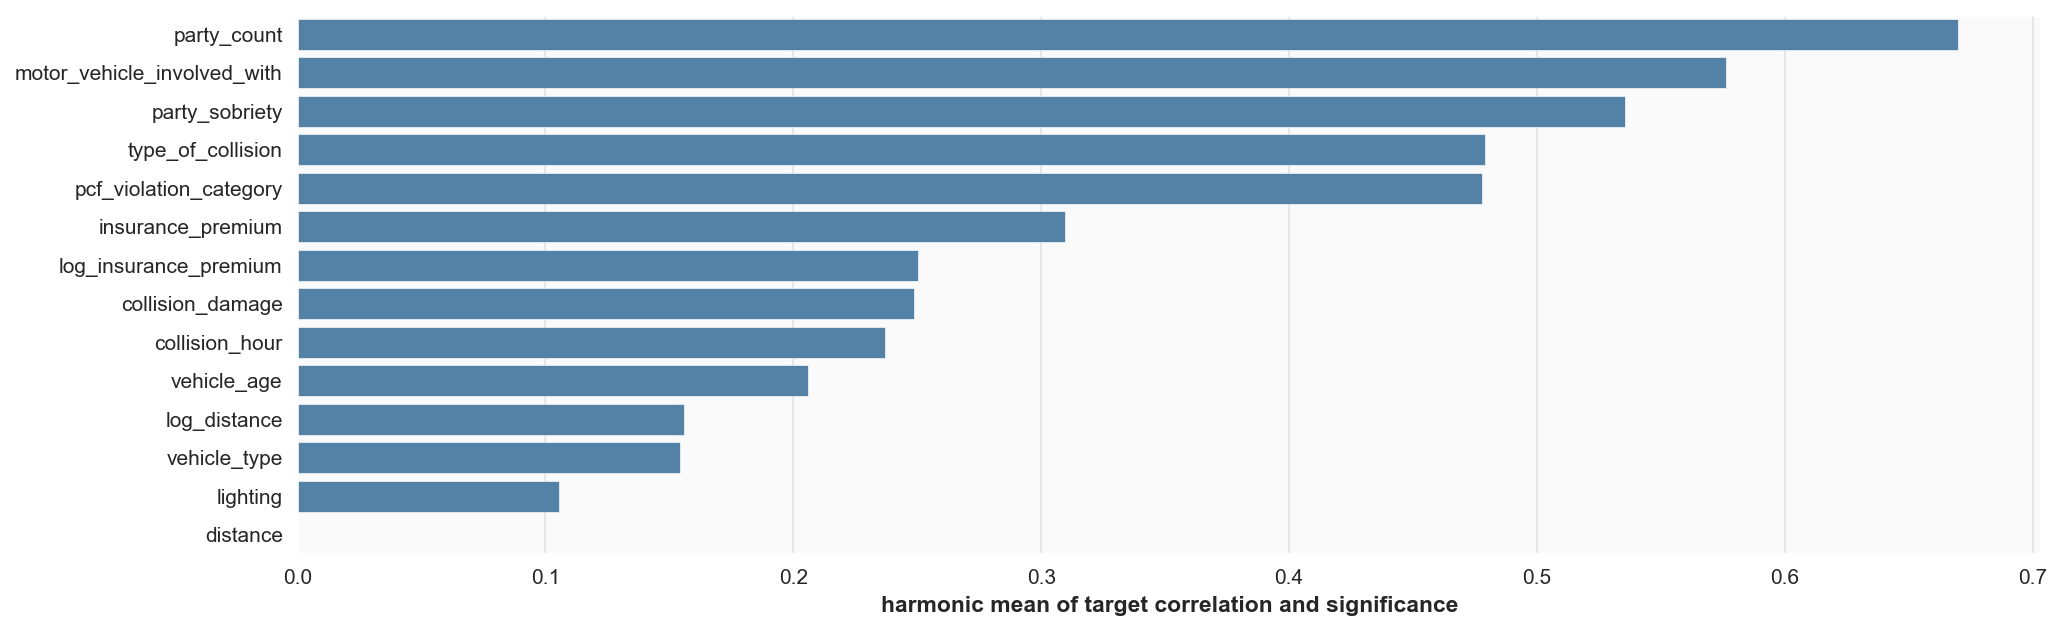

In [172]:
target_correlation_significance(data, TARGET, interval_features)

### Mutual info

,k_3,k_5,k_7,average
motor_vehicle_involved_with,0.092,0.090,0.090,0.091
party_count,0.090,0.090,0.089,0.090
type_of_collision,0.072,0.069,0.068,0.069
pcf_violation_category,0.058,0.058,0.055,0.057
party_sobriety,0.054,0.052,0.053,0.053
log_insurance_premium,0.022,0.020,0.020,0.021
insurance_premium,0.019,0.018,0.021,0.019
vehicle_type,0.014,0.012,0.012,0.013
collision_damage,0.012,0.012,0.010,0.011
collision_hour,0.009,0.009,0.008,0.009


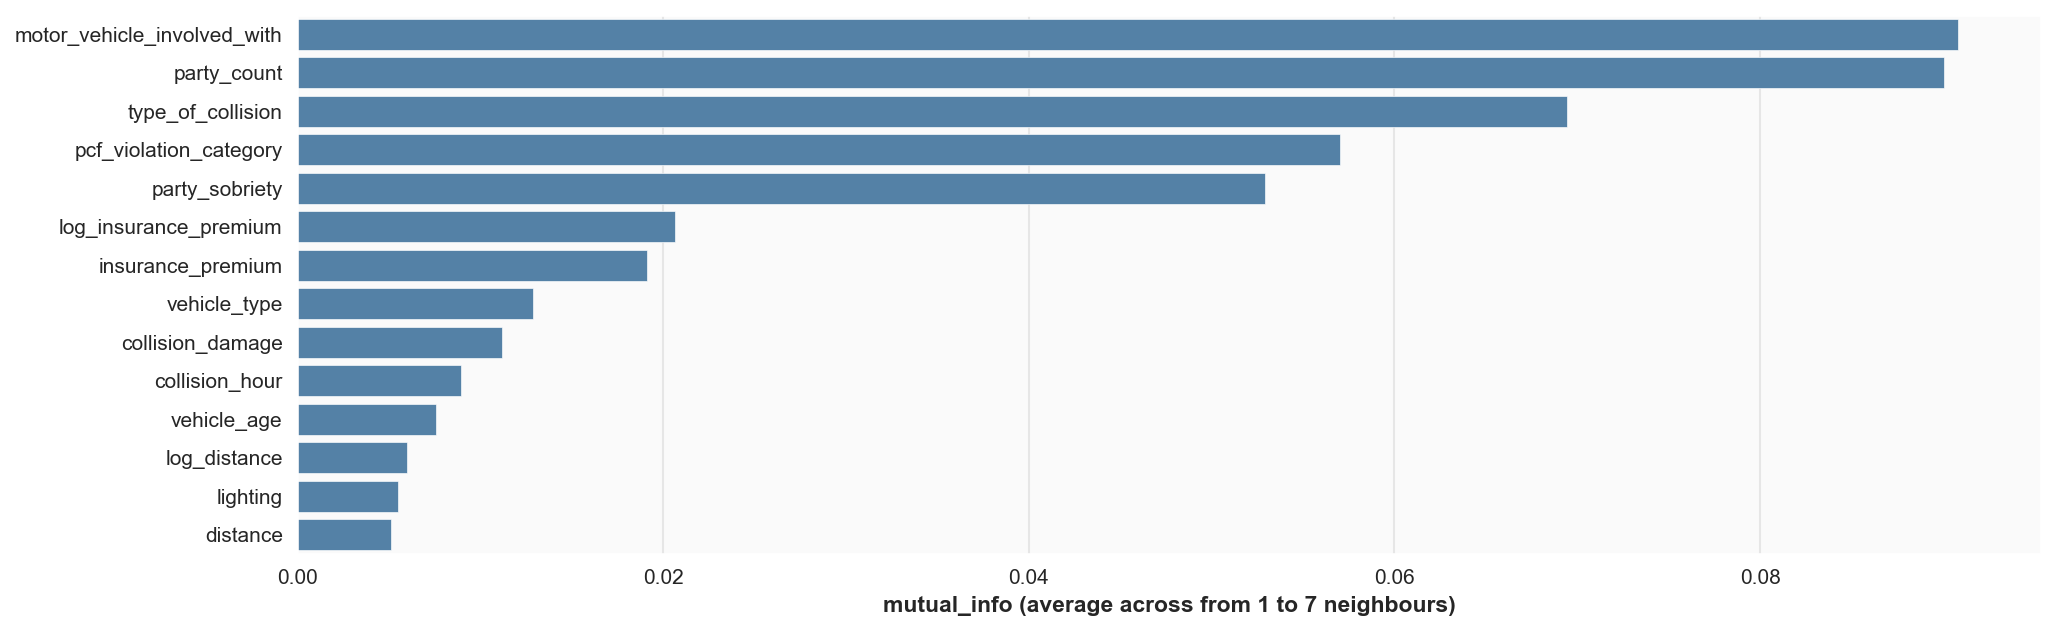

CPU times: total: 10.6 s
Wall time: 11 s


In [173]:
%%time
mutual_info(data, TARGET, task='classification', min_neighbors=3, max_neighbors=7)

> Анализ с помощью библиотеки `Phik` и с применением `Mutual info` в целом подтверждают правильность выбора признаков.  
> Вероятно, некоторые из отобранных признаков можно будет исключить после проверки на модели.

### Баланс целевого признака

In [174]:
data[TARGET].value_counts()

1    28299
0    27861
Name: at_fault, dtype: int64

> Целевой признак имеет небольшой дисбаланс.

## Model

### Выбор метрики для оптимизации

> 1. Общая поставленная задача "*создать систему, которая могла бы оценить риск ДТП по выбранному маршруту движения*" невыполнима ввиду, как минимум, отсутствия необходимых данных. Как и 3 других формулировки задачи.
> 1. Поскольку задание требует все же создать какую-нибудь модель, то, исходя из имеющихся данных, это будет модель, определяющая, виновен ли водитель определенного автомобиля в ДТП.
> 1. Поскольку в описании задания такая постановка задачи никак не затронута, то неизвестно, с какой целью мы создаем модель (то есть неизвестна бизнес-метрика).
> 1. Остается самостоятельно додумать бизнес-метрику и соотвествующую ей метрику для оптимизации модели.
> 1. Предположим, бизнес-задача состоит в том, чтобы максимально снизить вероятность водителя стать виновником ДТП.
> 1. Для этого необходимо как можно более полно выявить всех, кто мог бы стать виновником ДТП, чтобы не допустить их к управлению.
> 1. В качестве метрики для оптимизации можно использовать `recall`.
> 1. Существует опасность перестараться. Например, признав всех водителей потенциальными виновниками (и запретив им доступ к управлению), можно добиться максимального значения метрики `recall`. С учетом этого, а также того, что бизнес-метрика в задании не заявлена, метрика `f1` выглядит наиболее сбалансированным вариантом.

### Подготовка данных

#### Выделение признаков и целевой переменной

In [175]:
X = data.drop(TARGET, axis=1)
Y = data[TARGET]

X.shape, Y.shape

((56160, 14), (56160,))

#### Разделение на обучающую и валидационную выборки

In [176]:
X_train, X_valid, Y_train, Y_valid = train_test_split(X, Y, test_size=VALID_FRAC, stratify=Y, random_state=RS)

X_train.shape, Y_train.shape, X_valid.shape, Y_valid.shape

((44928, 14), (44928,), (11232, 14), (11232,))

### Preprocessing

#### Селекторы числовых и категориальных признаков

In [177]:
num_selector = make_column_selector(dtype_include='number')
cat_selector = make_column_selector(dtype_exclude='number')

#### Предбработка числовых признаков

In [178]:
num_preprocessor = make_pipeline(
#                                  IterativeImputer(initial_strategy='mean', random_state=RS),
                                 StandardScaler(),
#                                  SplineTransformer(),
                                )

#### Предбработка категориальных признаков

Раздельно для линейных моделей и моделей на базе деревьев.

In [179]:
# for linear models
cat_preprocessor_linr = OneHotEncoder(drop='first', handle_unknown='ignore')

# for tree models
cat_preprocessor_tree = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)

#### Объединение предобработки числовых и категориальных признаков

In [180]:
# for linear models
preprocessing_linr = make_column_transformer(
                                             (num_preprocessor, num_selector),
                                             (cat_preprocessor_linr, cat_selector),
#                                              remainder='drop'
                                            )
# for tree models
preprocessing_tree = make_column_transformer(
                                             (num_preprocessor, num_selector),
                                             (cat_preprocessor_tree, cat_selector),
#                                              remainder='drop'
                                            )

#### Pipelines' table

In [181]:
pipelines = [
             Pipeline([
                       ('preprocessing_linr', preprocessing_linr),
                       ('DC', DummyClassifier())
                      ]),
    
             Pipeline([
                       ('preprocessing_linr', preprocessing_linr),
                       ('RC', RidgeClassifier(random_state=RS))
                      ]),

             Pipeline([
                       ('preprocessing_linr', preprocessing_linr),
                       ('SGDC', SGDClassifier(random_state=RS))
                      ]),
    
             Pipeline([
                       ('preprocessing_tree', preprocessing_tree),
                       ('HGBC', HistGradientBoostingClassifier(random_state=RS))
                      ]),    
    
             Pipeline([
                       ('preprocessing_tree', preprocessing_tree),
                       ('RFC', RandomForestClassifier(random_state=RS))
                      ]),
    
             Pipeline([
                       ('preprocessing_tree', preprocessing_tree),
                       ('XGBC', XGBClassifier(objective='binary:logistic', eval_metric='auc', random_state=RS))
                      ]),
             Pipeline([
                       ('preprocessing_tree', preprocessing_tree),
                       ('LGBMC', LGBMClassifier(force_row_wise=True, random_state=RS))
                  #      ('LGBMRtt', DummyClassifier())                                      # заглушка для Windows_7
                      ]),
            ]

names = ['Dummy', 'Ridge', 'SGD', 'HistGB', 'RandomForest', 'XGBoost', 'LightGBM']

short_names = ['DC', 'RC', 'SGDC', 'HGBC', 'RFC', 'XGBC', 'LGBMC']

models = pd.DataFrame(
                      data={'name': names,
                            'short_name': short_names,
                            'model': pipelines,
                           },
                     )
models

,name,short_name,model
0,Dummy,DC,"(ColumnTransformer(transformers=[('pipeline',\n Pipeline(steps=[..."
1,Ridge,RC,"(ColumnTransformer(transformers=[('pipeline',\n Pipeline(steps=[..."
2,SGD,SGDC,"(ColumnTransformer(transformers=[('pipeline',\n Pipeline(steps=[..."
3,HistGB,HGBC,"(ColumnTransformer(transformers=[('pipeline',\n Pipeline(steps=[..."
4,RandomForest,RFC,"(ColumnTransformer(transformers=[('pipeline',\n Pipeline(steps=[..."
5,XGBoost,XGBC,"(ColumnTransformer(transformers=[('pipeline',\n Pipeline(steps=[..."
6,LightGBM,LGBMC,"(ColumnTransformer(transformers=[('pipeline',\n Pipeline(steps=[..."


В таблице моделей необходимо оставить только те, что есть в списке ESTIMATOR_LIST (то есть удалить лишние).

In [182]:
for item in range(models.shape[0]):
    if models.loc[item,'name'] not in ESTIMATOR_LIST:
        models = models.drop(item, axis=0)
        
models = models.reset_index(drop=True)

models

,name,short_name,model
0,Dummy,DC,"(ColumnTransformer(transformers=[('pipeline',\n Pipeline(steps=[..."
1,Ridge,RC,"(ColumnTransformer(transformers=[('pipeline',\n Pipeline(steps=[..."
2,SGD,SGDC,"(ColumnTransformer(transformers=[('pipeline',\n Pipeline(steps=[..."
3,HistGB,HGBC,"(ColumnTransformer(transformers=[('pipeline',\n Pipeline(steps=[..."
4,XGBoost,XGBC,"(ColumnTransformer(transformers=[('pipeline',\n Pipeline(steps=[..."
5,LightGBM,LGBMC,"(ColumnTransformer(transformers=[('pipeline',\n Pipeline(steps=[..."


### Подбор гиперпараметров

#### Objective functions для Optuna

In [183]:
def objective_DC(trial):

    params = {
              'DC__strategy': trial.suggest_categorical('DC__strategy', ['most_frequent','prior','stratified','uniform']),
             }

    model.set_params(**params)
    cv_SKF = StratifiedKFold(n_splits=N_CV)
    
    return cross_val_score(model, X_train, Y_train, scoring=SCORING, cv=cv_SKF, n_jobs=-1).mean()

In [184]:
def objective_RC(trial):

    params = {
              'RC__alpha': trial.suggest_float('RC__alpha', 0.1, 10.0, log=True),
              'RC__class_weight': trial.suggest_categorical('RC__class_weight', [None,'balanced']),
              'RC__max_iter': trial.suggest_int('RC__max_iter', 100, 1000, log=True),
             }
    
    model.set_params(**params)
    cv_SKF = StratifiedKFold(n_splits=N_CV)
    
    return cross_val_score(model, X_train, Y_train, scoring=SCORING, cv=cv_SKF, n_jobs=-1).mean()

In [185]:
def objective_SGDC(trial):

    params = {
              'SGDC__loss': trial.suggest_categorical('SGDC__loss', ['hinge','log_loss']),
              'SGDC__alpha': trial.suggest_float('SGDC__alpha', 1e-5, 1e-1, log=True),
              'SGDC__class_weight': trial.suggest_categorical('SGDC__class_weight', [None,'balanced']),
              'SGDC__max_iter': trial.suggest_int('SGDC__max_iter', 100, 1000, log=True),
             }
    
    model.set_params(**params)
    cv_SKF = StratifiedKFold(n_splits=5)
    
    return cross_val_score(model, X_train, Y_train, scoring=SCORING, cv=cv_SKF, n_jobs=-1).mean()

In [186]:
def objective_HGBC(trial):

    params = {
              'HGBC__max_depth': trial.suggest_int('HGBC__max_depth', 2, 200),
              'HGBC__max_leaf_nodes': trial.suggest_int('HGBC__max_leaf_nodes', 2, 100),
              'HGBC__learning_rate': trial.suggest_float('HGBC__learning_rate', 0.01, 1.0, log=True),
              'HGBC__max_iter': trial.suggest_int('HGBC__max_iter', 10, 500, log=True),
#               'HGBC__l2_regularization': trial.suggest_float('HGBC__l2_regularization', 0.001, 1000),
              'HGBC__max_bins': trial.suggest_int('HGBC__max_bins', 5, 255),
             }
    model.set_params(**params)
    cv_SKF = StratifiedKFold(n_splits=N_CV)
    
    return cross_val_score(model, X_train, Y_train, scoring=SCORING, cv=cv_SKF, n_jobs=-1).mean()

In [187]:
def objective_RFC(trial):

    params = {
              'RFC__n_estimators': trial.suggest_int('RFC__n_estimators', 50, 1000, log=True),
              'RFC__max_depth': trial.suggest_int('RFC__max_depth', 1, 50),
              'RFC__class_weight': trial.suggest_categorical('RFC__class_weight', ['balanced', 'balanced_subsample', None]),
             }
    model.set_params(**params)
    cv_SKF = StratifiedKFold(n_splits=5)
    
    return cross_val_score(model, X_train, Y_train, scoring=SCORING, cv=cv_SKF, n_jobs=-1).mean()

In [188]:
def objective_XGBC(trial):

    params = {
              'XGBC__max_depth': trial.suggest_int('XGBC__max_depth', 1, 20),
              'XGBC__n_estimators': trial.suggest_int('XGBC__n_estimators', 10, 200, log=True),
              'XGBC__subsample': trial.suggest_float('XGBC__subsample', 0.3, 1.0),
#               'XGBC__colsample_bytree': trial.suggest_float('XGBC__colsample_bytree', 0.3, 1.0),
              'XGBC__scale_pos_weight': trial.suggest_float('XGBC__scale_pos_weight', 0.3, 0.7),
              'XGBC__learning_rate': trial.suggest_float('XGBC__learning_rate', 0.01, 0.99),
              'XGBC__gamma': trial.suggest_float('XGBC__gamma', 0.1, 10, log=True),
              'XGBC__min_child_weight': trial.suggest_float('XGBC__min_child_weight', 0.1, 10, log=True),
              'XGBC__lambda': trial.suggest_float('XGBC__lambda', 0.1, 10, log=True),
#               'XGBC__max_leaves': trial.suggest_int('XGBC__max_leaves', 2, 200, log=True),
#               'XGBC__max_bin': trial.suggest_int('XGBC__max_bin', 10, 1000, log=True),
             }
    model.set_params(**params)
    cv_SKF = StratifiedKFold(n_splits=N_CV)
    
    return cross_val_score(model, X_train, Y_train, scoring=SCORING, cv=cv_SKF, n_jobs=-1).mean()

In [189]:
def objective_LGBMC(trial):

    params = {
              'LGBMC__boosting_type': trial.suggest_categorical('LGBMC__boosting_type', ['gbdt','dart','goss']),
              'LGBMC__num_leaves': trial.suggest_int('LGBMC__num_leaves', 100, 1000, log=True),
              'LGBMC__max_depth': trial.suggest_int('LGBMC__max_depth', 1, 50),
              'LGBMC__n_estimators': trial.suggest_int('LGBMC__n_estimators', 10, 200, log=True),
              'LGBMC__learning_rate': trial.suggest_float('LGBMC__learning_rate', 0.005, 0.2),
              'LGBMC__subsample_for_bin': trial.suggest_int('LGBMC__subsample_for_bin', 1e4, 1e6, log=True),
              'LGBMC__reg_alpha': trial.suggest_float('LGBMC__reg_alpha', 0.05, 10, log=True),
              'LGBMC__reg_lambda': trial.suggest_float('LGBMC__reg_lambda', 0, 1),
             }
    
    model.set_params(**params)
    cv_SKF = StratifiedKFold(n_splits=5)
    
    return cross_val_score(model, X_train, Y_train, scoring=SCORING, cv=cv_SKF, n_jobs=-1).mean()

#### Optuna call

In [190]:
for item in range(models.shape[0]):
    
    print('—' * 60)
    print(f"{CR}{models.loc[item,'name']} hyperparams tuning...")
    
    model = models.loc[item,'model']

    # создание объекта optuna.study
    study = optuna.create_study(
                                study_name=models.loc[item,'name'],
                                direction="maximize",
                                sampler=optuna.samplers.TPESampler(seed=RS)
                               )

    # оптимизация (подбор гиперпараметров)
    study.optimize(eval(f"objective_{models.loc[item,'short_name']}"),
                   n_trials=N_TRIALS, timeout=TIMEOUT, show_progress_bar=True, n_jobs=-1)

    # извлечение и обучение лучшей модели – здесь можно сделать обучение на полном наборе данных (X,Y)
    model.set_params(**study.best_params).fit(X_train, Y_train)

    # сохранение результатов в таблице моделей
    models.loc[item,'model'] = model
    models.loc[item,'study'] = study
#     models.loc[item,'features'] = ', '.join(extract_final_features(model))   # пока недостаточно универсально
    models.loc[item,'score'] = study.best_value

    print(f'{CR}{f.BOLD}{study.study_name}{f.END}{CR}')
    print(f'Количество попыток: {len(study.trials)}')
    print(f'Лучший результат: {f.BOLD}{study.best_value:0.4f}{f.END}{CR}')
    print('Комбинация гиперпараметров:')
    print(json.dumps(study.best_params, indent=1, sort_keys=True), f'{CR}')

————————————————————————————————————————————————————————————

Dummy hyperparams tuning...


Best trial: 16. Best value: 0.67012: 100%|██████████| 100/100 [00:12<00:00,  7.84it/s, 12.75/300 seconds]



Dummy

Количество попыток: 100
Лучший результат: 0.6701

Комбинация гиперпараметров:
{
 "DC__strategy": "most_frequent"
} 

————————————————————————————————————————————————————————————

Ridge hyperparams tuning...


Best trial: 48. Best value: 0.681813: 100%|██████████| 100/100 [00:29<00:00,  3.41it/s, 29.31/300 seconds]



Ridge

Количество попыток: 100
Лучший результат: 0.6818

Комбинация гиперпараметров:
{
 "RC__alpha": 3.6500839421191085,
 "RC__class_weight": null,
 "RC__max_iter": 176
} 

————————————————————————————————————————————————————————————

SGD hyperparams tuning...


Best trial: 42. Best value: 0.701161: 100%|██████████| 100/100 [00:25<00:00,  3.85it/s, 25.99/300 seconds]


... (3 outputs left out)

Best trial: 68. Best value: 0.671534: 100%|██████████| 100/100 [01:43<00:00,  1.04s/it, 103.92/300 seconds]



XGBoost

Количество попыток: 100
Лучший результат: 0.6715

Комбинация гиперпараметров:
{
 "XGBC__gamma": 3.039320362557164,
 "XGBC__lambda": 6.617626479375594,
 "XGBC__learning_rate": 0.2348943849943324,
 "XGBC__max_depth": 5,
 "XGBC__min_child_weight": 9.059464911774597,
 "XGBC__n_estimators": 197,
 "XGBC__scale_pos_weight": 0.655287574223303,
 "XGBC__subsample": 0.3671927665424701
} 

————————————————————————————————————————————————————————————

LightGBM hyperparams tuning...


Best trial: 58. Best value: 0.708391: 100%|██████████| 100/100 [00:59<00:00,  1.69it/s, 59.29/300 seconds]



LightGBM

Количество попыток: 100
Лучший результат: 0.7084

Комбинация гиперпараметров:
{
 "LGBMC__boosting_type": "gbdt",
 "LGBMC__learning_rate": 0.09976256994833041,
 "LGBMC__max_depth": 6,
 "LGBMC__n_estimators": 199,
 "LGBMC__num_leaves": 316,
 "LGBMC__reg_alpha": 0.1510112085507956,
 "LGBMC__reg_lambda": 0.5975962580665181,
 "LGBMC__subsample_for_bin": 20288
} 



#### Визуализация результатов подбора гиперпараметров

Для корректировки процесса подбора.

In [191]:
# for item in range(models.shape[0]):
#     plot_Optuna(models.loc[item,'study'], 'plot_slice', models.loc[item, 'name'])
# #     plot_Optuna(models.loc[item,'study'], 'plot_param_importances', models.loc[item, 'name'])
#     plot_Optuna(models.loc[item,'study'], 'plot_optimization_history', models.loc[item, 'name'])

## Анализ моделей

### Дополнительные метрики

В дополнение к основной метрике, полученной во время подбора гиперпараметров, можно сравнить метрики, рассчитанные с помощью кроссвалидации. Можно изменять параметры кроссвалидации.  
Метрики рассчитываются как для обучающей, так и валидационной выборки.

In [192]:
%%time
# дополнительные метрики моделей
models = add_model_metrics(models, X_train, Y_train, X_valid, Y_valid, cv=N_CV,
                           scoring_list=['f1','recall','precision'])

models.drop(['short_name','model','study','best_params'], axis=1).sort_values('score', ascending=False).reset_index(drop=True)

Performing cross_val_score with cv=5 and scoring_list=['f1', 'recall', 'precision']:
f1_train... done
f1_test... done
recall_train... done
recall_test... done
precision_train... done
precision_test... done
CPU times: total: 125 ms
Wall time: 32.1 s


,name,score,f1_train,f1_test,recall_train,recall_test,precision_train,precision_test
0,LightGBM,0.708,0.708,0.708,0.627,0.647,0.815,0.782
1,HistGB,0.708,0.708,0.697,0.621,0.660,0.822,0.737
2,SGD,0.701,0.701,0.686,0.693,0.627,0.725,0.770
3,Ridge,0.682,0.682,0.694,0.586,0.608,0.814,0.808
4,XGBoost,0.672,0.672,0.675,0.542,0.557,0.884,0.858
5,Dummy,0.670,0.670,0.670,1.000,1.000,0.504,0.504


### Confusion Matrix Display

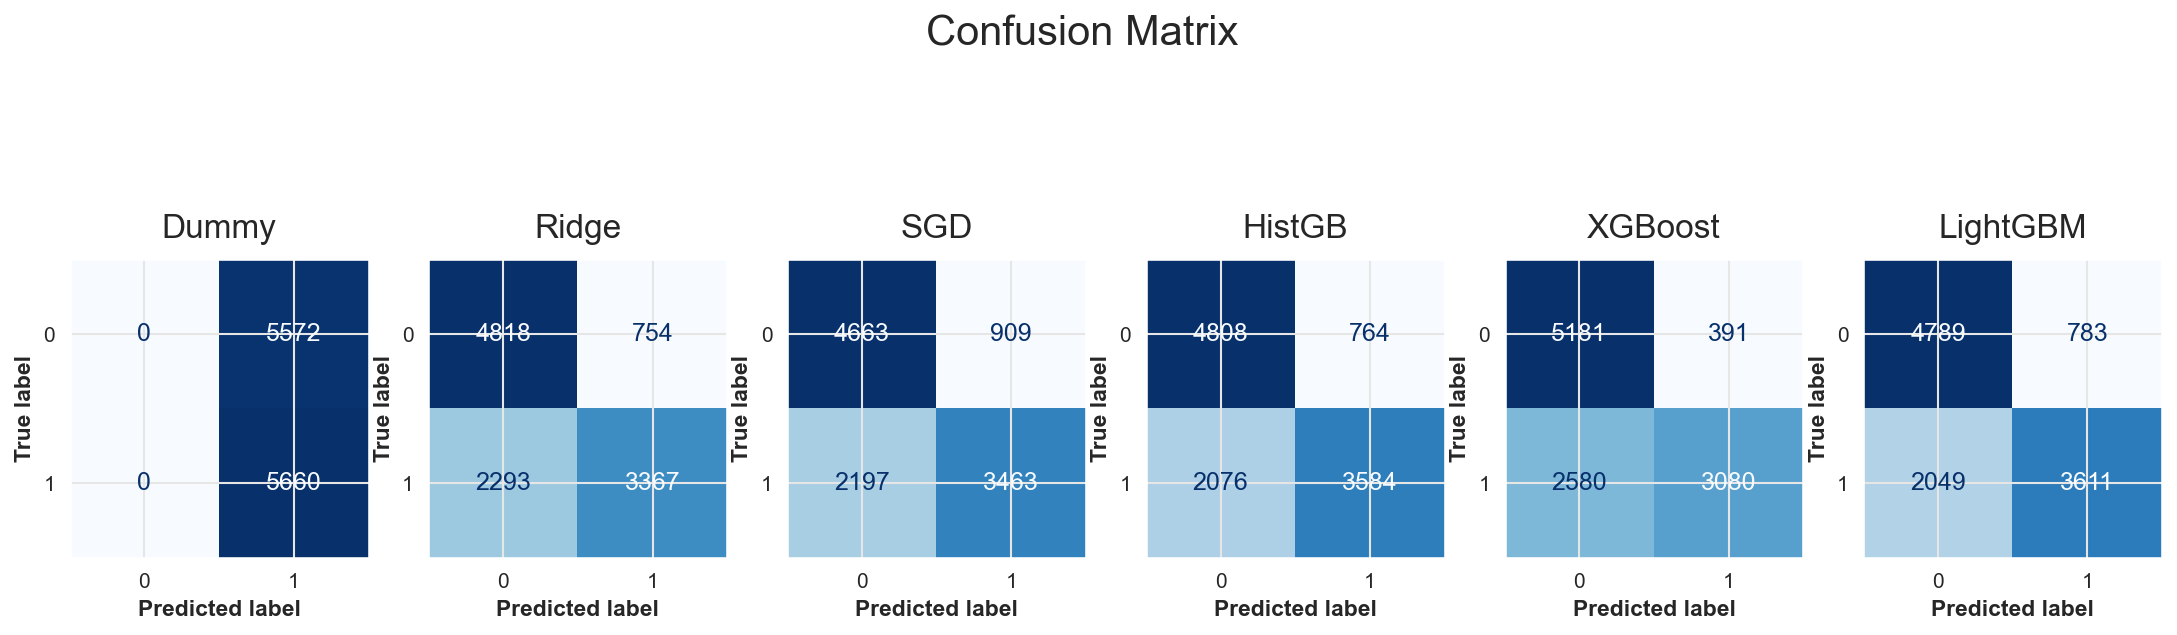

In [193]:
n_plot = models.shape[0]

fig, ax = plt.subplots(figsize=(18,5), ncols=n_plot, dpi=PLOT_DPI)
fig.suptitle('Confusion Matrix', fontsize=20, y=1.02)

for item in range(models.shape[0]):
    
    ConfusionMatrixDisplay.from_estimator(models.loc[item,'model'].fit(X_train, Y_train),
                                          X_valid, Y_valid,
                                          ax=ax[item], colorbar=False, cmap='Blues',
                                          values_format='.0f')
    ax[item].set_title(f"{models.loc[item,'name']}")

> Чаще всего модели ошибаются, неверно предсказывая положительный класс. Возможно, стоит изменить порог отнесения к классу.

### Выбор лучшей модели

In [194]:
SCORE_FIELD = 'score'      # название поля для выбора лучшей модели
LESS_IS_BETTER = False     # для направления сортировки

# название модели с лучшим score
best_model_name = models.sort_values(SCORE_FIELD, ascending=LESS_IS_BETTER).reset_index(drop=True).loc[0,'name']

# выбор модели из таблицы
model = models[models.name == best_model_name].model.values[0]

In [195]:
best_model_name

'LightGBM'

### Важность признаков

CPU times: total: 9 s
Wall time: 6.09 s


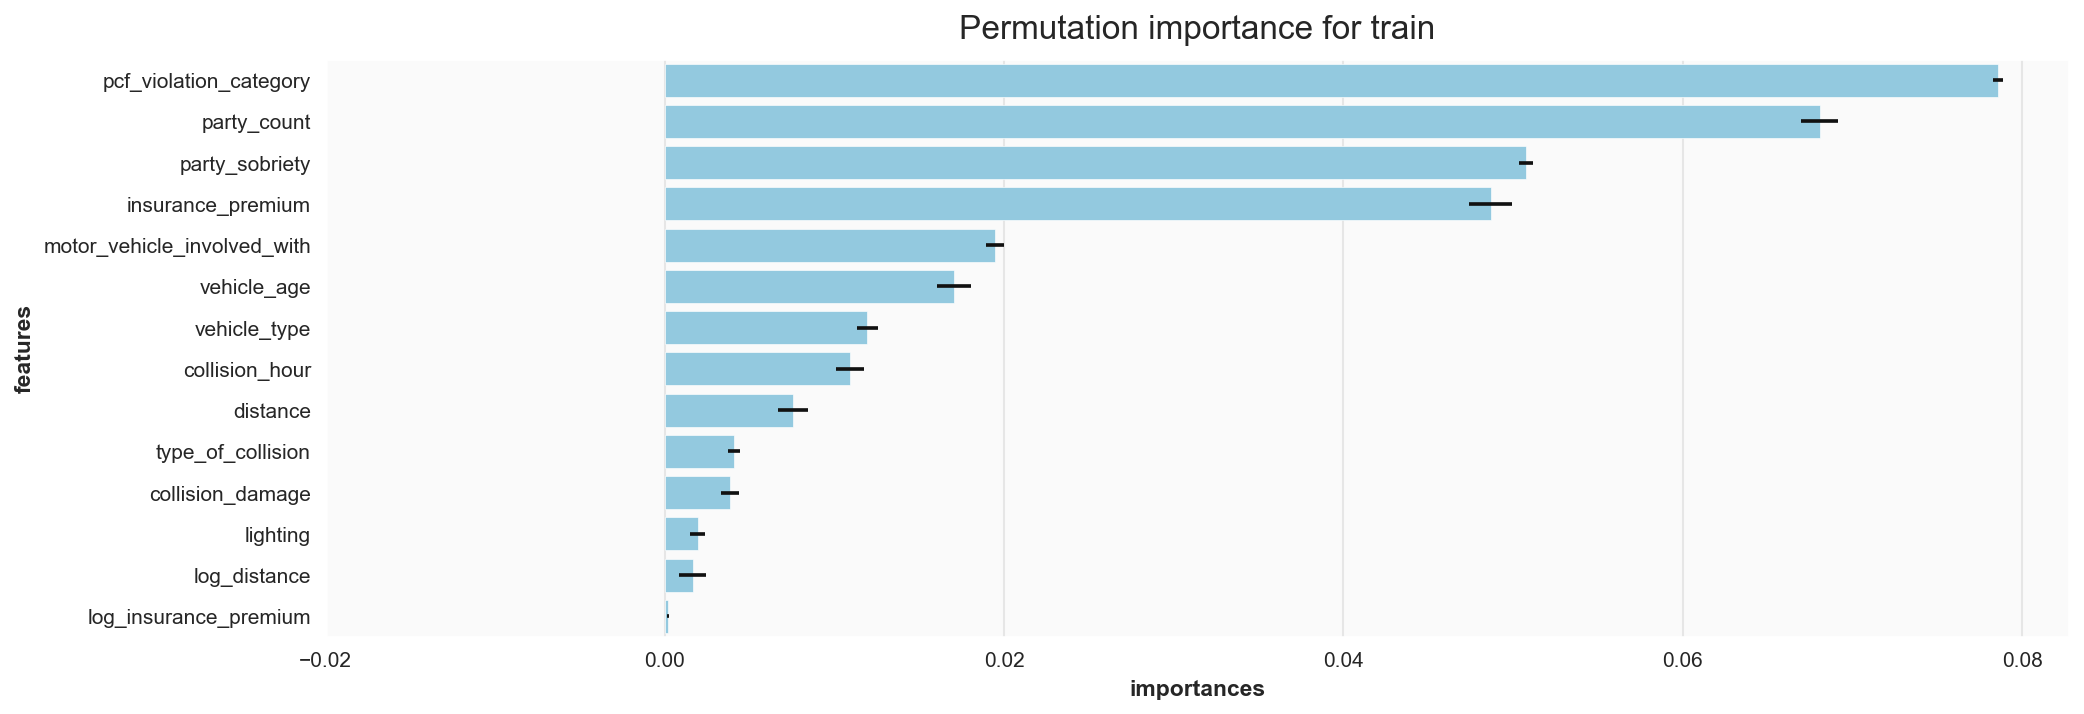

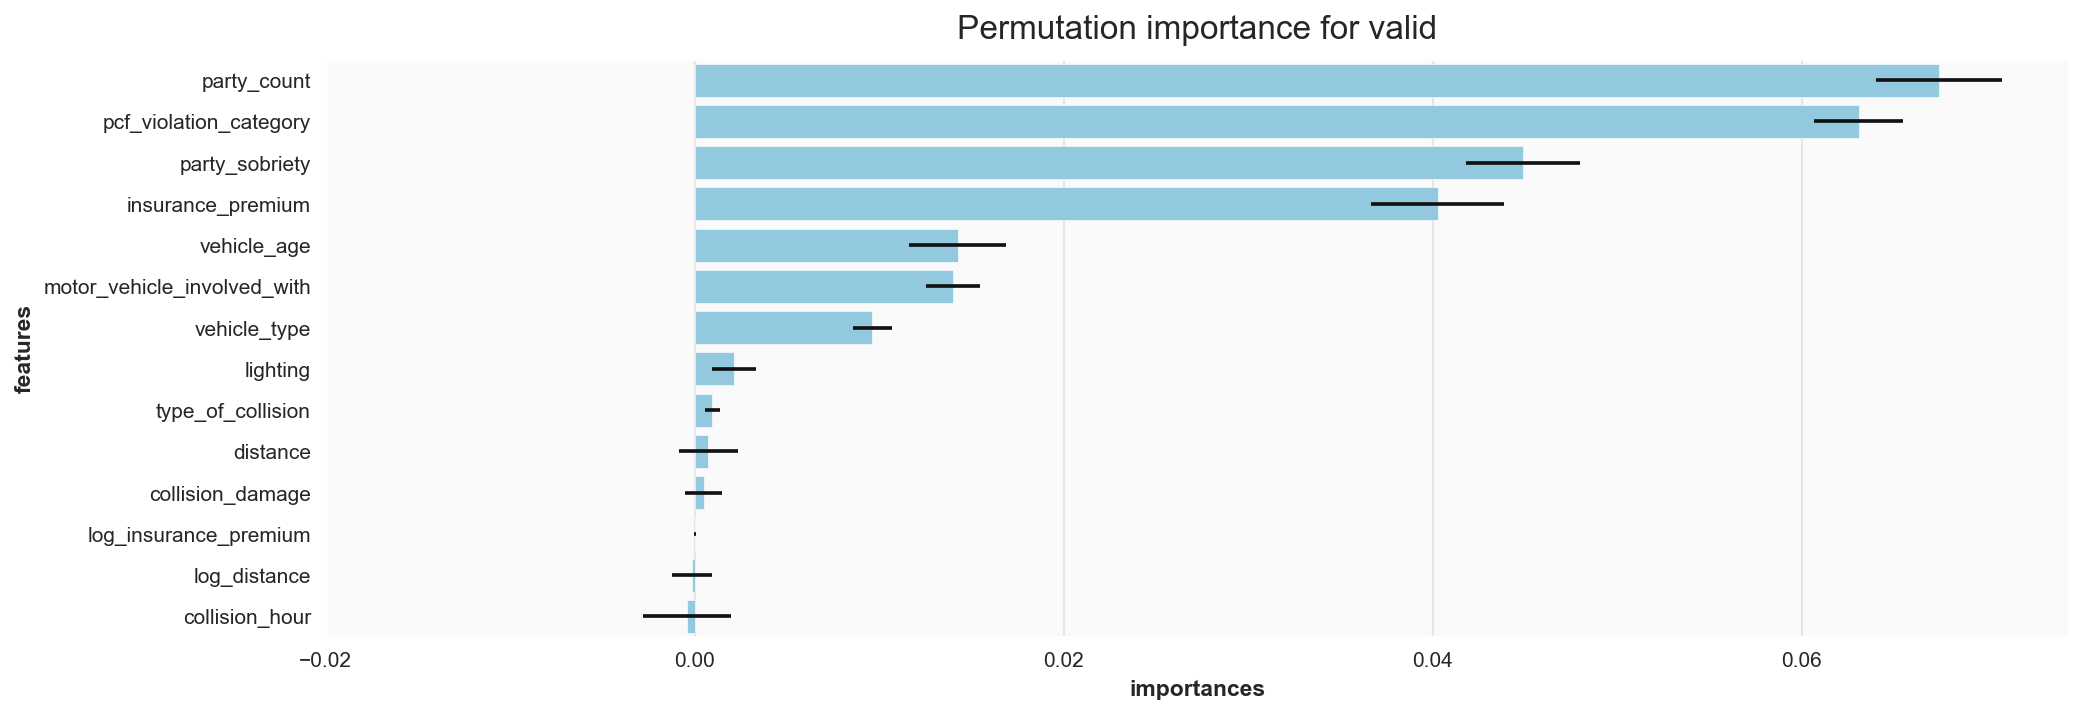

In [196]:
%%time

# permutation importance for train
plot_feature_importances(
                         'Permutation importance for train',
                         # извлечение списка признаков
                         model.feature_names_in_,
                         # вычисление важности признаков
                         permutation_importance(model,
                                                X_train, Y_train,
                                                scoring=SCORING, n_repeats=5, n_jobs=-1, random_state=RS)
                        )

# permutation importance for valid
plot_feature_importances(
                         'Permutation importance for valid',
                         # извлечение списка признаков
                         model.feature_names_in_,
                         # вычисление важности признаков
                         permutation_importance(model,
                                                X_valid, Y_valid,
                                                scoring=SCORING, n_repeats=5, n_jobs=-1, random_state=RS)
                        )

> Среди наиболее важных признаков только `insurance_premium` и `party_sobriety` известны до ДТП.  
> Если предполагается использовать модель, чтобы решить, допускать или нет водителя к управлению, то остается только `party_sobriety` (страховка применима только для личного автомобиля).
>
> То есть, такие данные малопригоды для такой задачи, если заказчик предполагает управление собственным автопарком.

> Логарифмирование признаков `distance` и `insurance_premium` не оправдало себя в лучшей модели (в линейных моделях, наоборот, помогает).
> 
> Влияние признаков существенно различается на обучающей и тестовой выборках.
>
> Возможно, исключив ненадежные признаки, можно сделать модель более стабильной.

### Дополнительное исследование одного из выявленных важных факторов

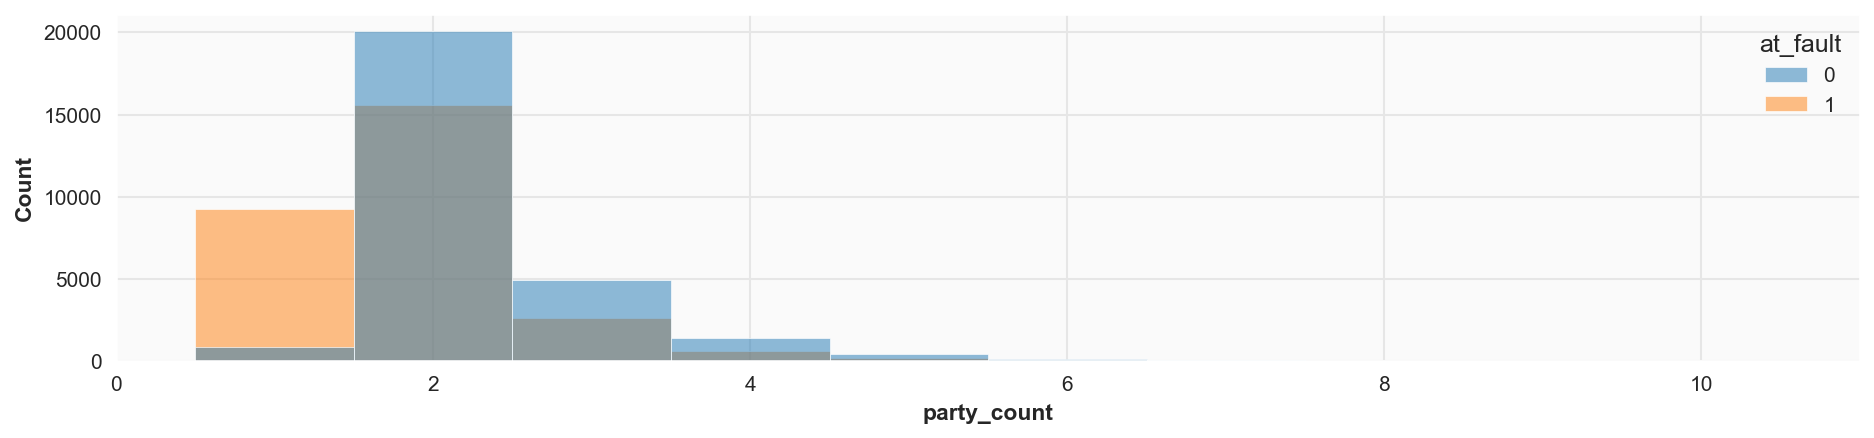

In [198]:
column = 'party_count'

df = data[[column, TARGET]].dropna(subset=[column])

fig, ax = plt.subplots(figsize=(15,3), dpi=PLOT_DPI)
sns.histplot(x=df[column], hue=data[TARGET], bins=bins_treshold, discrete=True, palette='tab10');

> В ДТП чаще один виновник, поэтому логично, что чем меньше участников, тем проще определить виновника.
>
> Можно оценить, какие нарушения приводят к одиночным авариям.

In [199]:
data[data.party_count == 1].groupby(['pcf_violation_category', TARGET]).party_count.count().unstack().fillna(0).astype(int)

at_fault,0,1
pcf_violation_category,,
automobile right of way,0,2
dui,13,2455
following too closely,0,11
improper passing,0,12
improper turning,15,3875
other,11,90
other hazardous violation,1,53
other than driver (or pedestrian),715,0
speeding,17,2352


> Как видно, есть 3 вида нарушений, являющихся причиной большей части одиночных аварий.  
> Например, превышение скорости.  
> Установка в машине неотключаемого предупреждающего устройства может снизить вероятность аварии.  
> Возможно, стоит рассмотреть применение неотключаемого ограничителя скорости (для избежания аварийных ситуаций в таких случаях существуют решения).

In [200]:
data[data.party_count == 1].groupby(['vehicle_type', TARGET]).party_count.count().unstack().fillna(0).astype(int)

at_fault,0,1
vehicle_type,,
coupe,276,5266
other,1,1
sedan,590,3971


> Далее видно, что одиночные аварии чаще всего устраивают на автомобилях с кузовом купе.  
> Компании стоит отказаться от таких автомобилей в пользу минивенов ))

---

## Вывод

### Краткий обзор проделанной работы

1. Данные загружены из удаленной БД и сохранены локально.
1. Проведено первичное исследование данных.
1. Выполнен анализ факторов ДТП.
1. Подготовлены данные для модели.
1. Создано несколько различных моделей.
1. Выбрана и проанализирована лучшая модель.
1. Проанализированы основные факторы, влияющие на вероятность ДТП.
1. Сделан вывод: насколько возможно создание адекватной системы оценки риска при выдаче авто.
1. Предложены дополнительные факторы, которые необходимо собирать, чтобы улучшить модель.

### Анализ поставленной задачи

На протяжении задания постановка задачи изменяется несколько раз:
1. "Создать систему, которая могла бы оценить риск ДТП по выбранному маршруту движения".
1. "Задача — понять, возможно ли предсказывать ДТП, опираясь на исторические данные одного из регионов".
1. "Создать модель предсказания ДТП (целевое значение — `at_fault` (виновник)".
1. "Создайте модель для оценки водительского риска".

А предоставленные данные описывают вообще другую задачу: является ли автомобиль (его водитель) виновником ДТП.

При такой неопределенности со стороны заказчика трудно ожидать качественный результат.

Модель создана, исходя из имеющихся данных и зафиксированного в задании целевого признака.

### Моделирование

Созданы несколько моделей, из которых выбрана лучшая: на базе алгоритма LightGBM.  
Оптимизация проводилась по метрике `f1`. В качестве дополнительных метрик использованы `recall` и `precision`. Модель имеет стабильные метрики как на обучающей, так и на тестовой выборках.

### Возможность создания адекватной системы оценки риска при выдаче авто

На основе предоставленных данных невозможно сделать вывод о "возможности создания адекватной системы оценки риска при выдаче авто".

Большая часть факторов из предоставленных данных не имеет отношения к этой задаче, поскольку они становятся известными только с момента ДТП. Чтобы оценить влияние этих факторов на ДТП, необходимо заранее знать маршрут, а также иметь данные обо всех(!) поездках (включая безаварийные) по тому же маршруту за тот же период.

Исходя из этого, идея анализа маршрута должна быть разложена на анализ отдельных участков, для которых необходимо собирать всю(!) информацию о трафике, включая безаварийный.

Значительная часть важных данных не соответствует потребностям заказчика, поскольку относится к личным автомобилям. Это влияет на область применимости модели.

С другой стороны, необходимо иметь больше информации о водителе и автомобиле.  
Из доступной информации это может быть:
- возраст водителя;
- стаж водителя;
- пол водителя;
- физическое состояние (можно сделать более-менее комплексную оценку, в том числе с применением ИИ);
- мощность двигателя;
- вес автомобиля;
- назначение автомобиля;
- общий и ежегодный пробег автомобиля;
- модель автомобиля.

### Риски и рекомендации

Поставленные задачи противоречат друг другу и предоставленным данным.

Данные за 2012 год неполны. Маловероятно, но все же это может внести искажение в результат.  
Судя по характеру данных, вряд ли они могли устареть за год или даже за 10 лет — можно было использовать весь набор данных.

Поскольку заказчик предполагает управление собственным автопарком, то некоторые важные для модели признаки будут неприменимы. И в целом область применимости модели не соответствует потребностям заказчика.

Обобщая.  
**Размытая и противоречивая постановка задачи, несоответствие предоставленных данных логично привели к созданию бесполезной модели. Несмотря на то, что модель имеет сносные метрики, область ее применимости вряд ли соответствует потребностям заказчика.**